# Section 2 – Task 3: Clustering with Different Algorithms

**Datasets:** `Dataset2/` — four synthetic 2-D point clouds  
**Algorithms:** K-Means · Agglomerative (single / complete / average / Ward) · DBSCAN  
**Metrics:** Silhouette ↑ · Davies–Bouldin ↓ · Calinski–Harabász ↑

> All datasets contain columns `x1`, `x2` (2-D coordinates, already numeric).  
> Data is standardised with `StandardScaler` before every distance-based algorithm.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                              calinski_harabasz_score)
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

import warnings, os
warnings.filterwarnings("ignore")
os.makedirs("plots", exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

NOISE_COLOR = "#d3d3d3"    # light grey: used ONLY for DBSCAN noise points
# Cluster palette: tab20 without its two greys (indices 14, 15) -> 18 non-grey colours,
# ordered so the strong tab10-like colours come first.
_t20 = plt.cm.tab20.colors
CLUSTER_PALETTE = [_t20[i] for i in list(range(0, 20, 2)) + list(range(1, 20, 2)) if i not in (14, 15)]
LINKAGES    = ["single", "complete", "average", "ward"]

def cluster_colors(labels, noise_label=-1):
    """Return a colour list; noise points → NOISE_COLOR."""
    unique  = sorted(set(labels) - {noise_label})
    col_map = {lbl: CLUSTER_PALETTE[i % len(CLUSTER_PALETTE)] for i, lbl in enumerate(unique)}
    col_map[noise_label] = NOISE_COLOR
    return [col_map[l] for l in labels]

def compute_scores(X, labels, noise_label=-1):
    """
    Compute silhouette, Davies-Bouldin, and Calinski-Harabász.
    DBSCAN noise points (label == -1) are EXCLUDED before computing scores
    (as required), and noise count / percentage are reported separately.
    """
    mask       = labels != noise_label
    n_noise    = int((~mask).sum())
    pct_noise  = 100.0 * n_noise / len(labels)
    n_clusters = len(set(labels[mask]))

    if n_clusters < 2 or mask.sum() < 2 or n_clusters >= mask.sum():
        return {"silhouette": np.nan, "davies_bouldin": np.nan,
                "calinski_harabasz": np.nan,
                "n_noise": n_noise, "pct_noise": pct_noise,
                "n_clusters": n_clusters}

    X_c, lbl_c = X[mask], labels[mask]
    sil = silhouette_score(X_c, lbl_c) if len(set(lbl_c)) >= 2 else np.nan
    db  = davies_bouldin_score(X_c, lbl_c)
    ch  = calinski_harabasz_score(X_c, lbl_c)
    return {"silhouette": sil, "davies_bouldin": db,
            "calinski_harabasz": ch,
            "n_noise": n_noise, "pct_noise": pct_noise,
            "n_clusters": n_clusters}

print("✓ Libraries and helpers loaded")

✓ Libraries and helpers loaded


## 1. Load and Inspect Datasets

In [2]:
BASE = os.path.join("datasets", "Dataset2")

datasets = {
    "Compact"      : pd.read_csv(os.path.join(BASE, "Compact.csv")),
    "Skewed"       : pd.read_csv(os.path.join(BASE, "Skewed.csv")),
    "Subclusters"  : pd.read_csv(os.path.join(BASE, "Subclusters.csv")),
    "WellSeparated": pd.read_csv(os.path.join(BASE, "wellSeperated.csv")),
}

print(f"{'Dataset':>15}  {'N':>5}  {'x1 range':>16}  {'x2 range':>16}")
print("-" * 60)
for name, d in datasets.items():
    print(f"{name:>15}  {d.shape[0]:>5}  "
          f"[{d.x1.min():>6.2f}, {d.x1.max():>6.2f}]  "
          f"[{d.x2.min():>6.2f}, {d.x2.max():>6.2f}]")


        Dataset      N          x1 range          x2 range
------------------------------------------------------------
        Compact    400  [-54.45,  29.89]  [-33.99,  40.37]
         Skewed    925  [-14.79,  13.84]  [-15.93,  25.95]
    Subclusters    400  [-20.98,  30.20]  [-12.28,  17.46]
  WellSeparated    335  [416.82, 698.54]  [201.33, 472.04]


## 2. Dataset Visualisation (Raw Data)

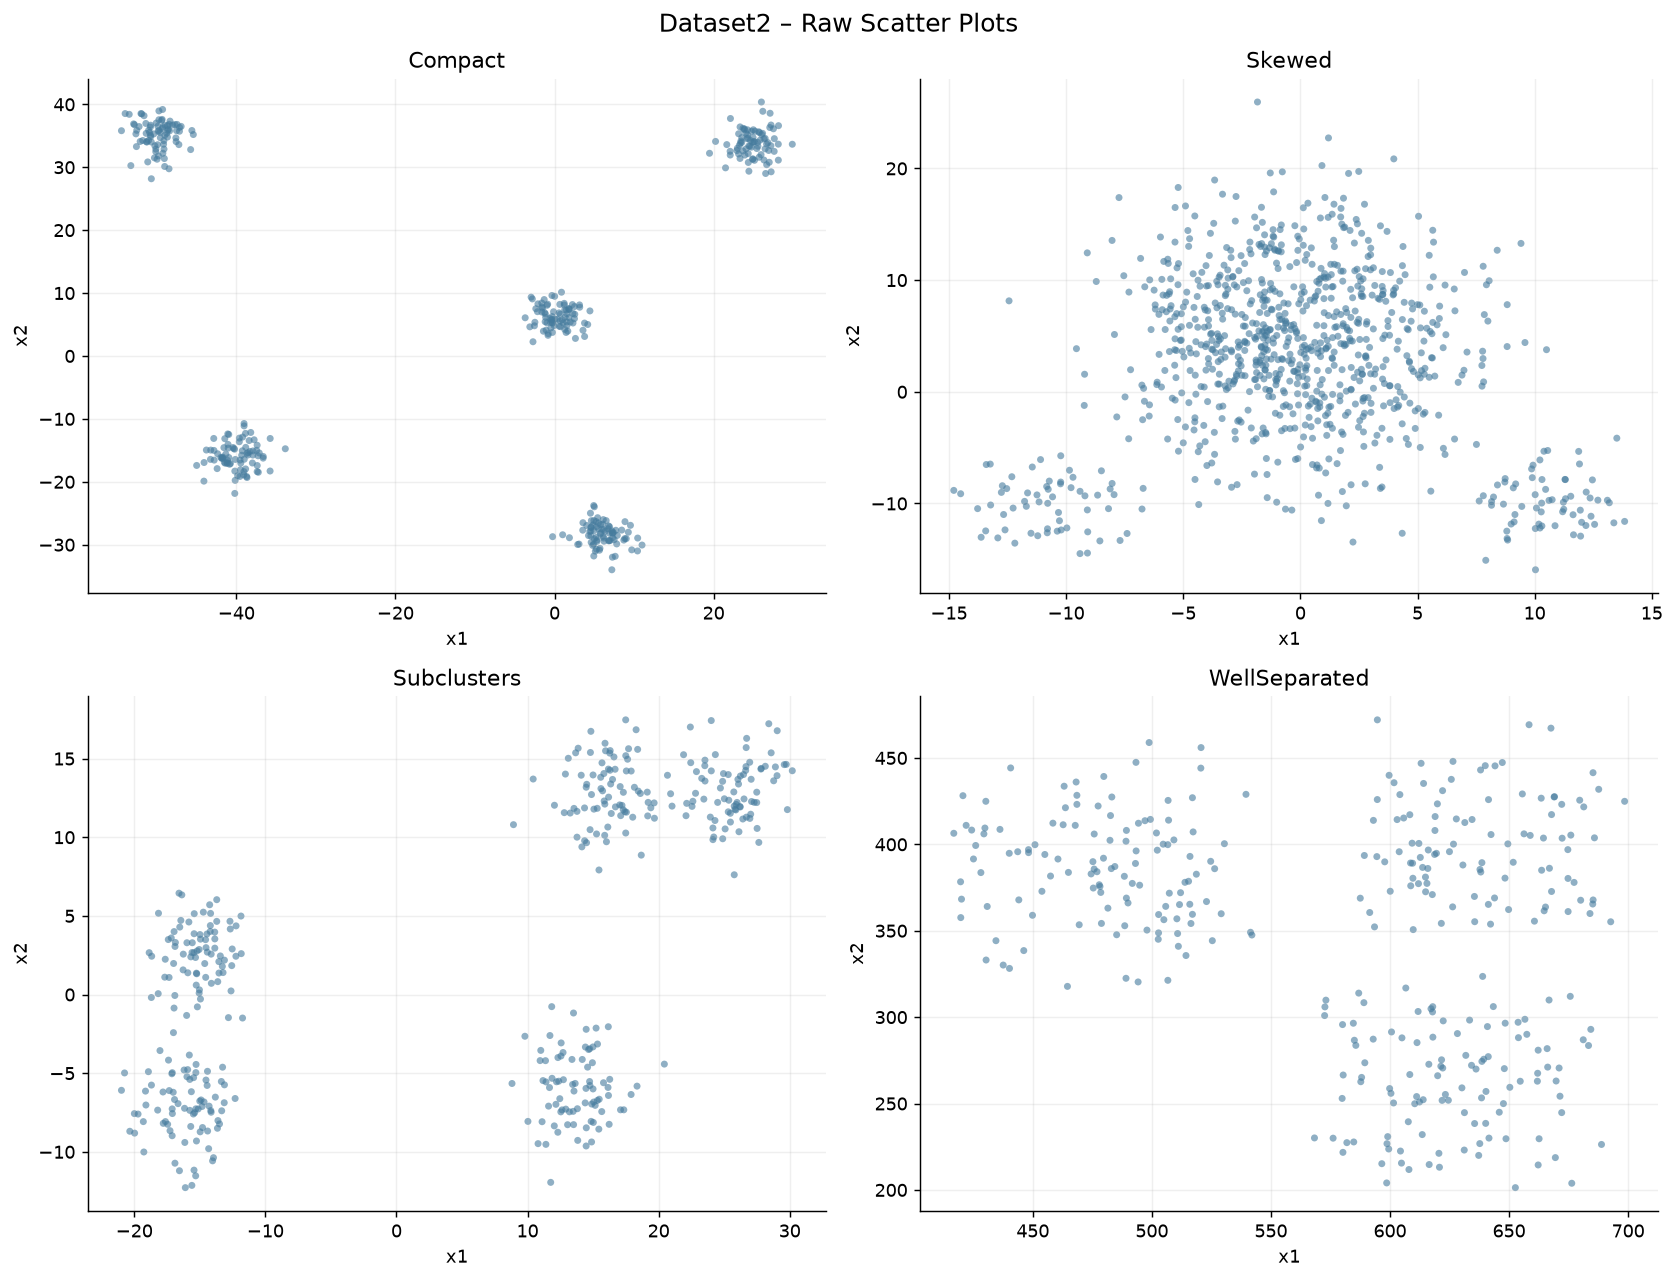

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (name, d) in zip(axes.flat, datasets.items()):
    ax.scatter(d.x1, d.x2, s=15, alpha=0.6, color="#457b9d", edgecolors="none")
    ax.set(title=name, xlabel="x1", ylabel="x2")
    ax.grid(alpha=0.2)

plt.suptitle("Dataset2 – Raw Scatter Plots", fontsize=14)
plt.tight_layout()
plt.savefig("plots/part3_raw_datasets.png", dpi=150, bbox_inches="tight")
plt.show()


**Visual inspection:**
- **Compact** — five tight, roughly circular, equally sized blobs with very large gaps.
- **Skewed** — one large, diffuse (high-variance) cloud plus two small, denser groups at the bottom
  left and bottom right that lie close to the edge of the large cloud: clusters of very
  **different size and variance**.
- **Subclusters** — four groups, of which the top-right one is itself made of **two adjacent
  sub-clusters** (5 blobs at a fine level, 4 at a coarse level); the two left groups are also
  fairly close to each other.
- **WellSeparated** — three roughly circular clusters with clear gaps (scales differ in raw units).

## 3. K-Means Clustering

### 3.1 k Selection via Elbow Method and Silhouette Score

        Dataset  Best-k  Max-Silhouette
------------------------------------------
        Compact       5  0.9133
         Skewed       3  0.4093
    Subclusters       4  0.7590
  WellSeparated       3  0.6137


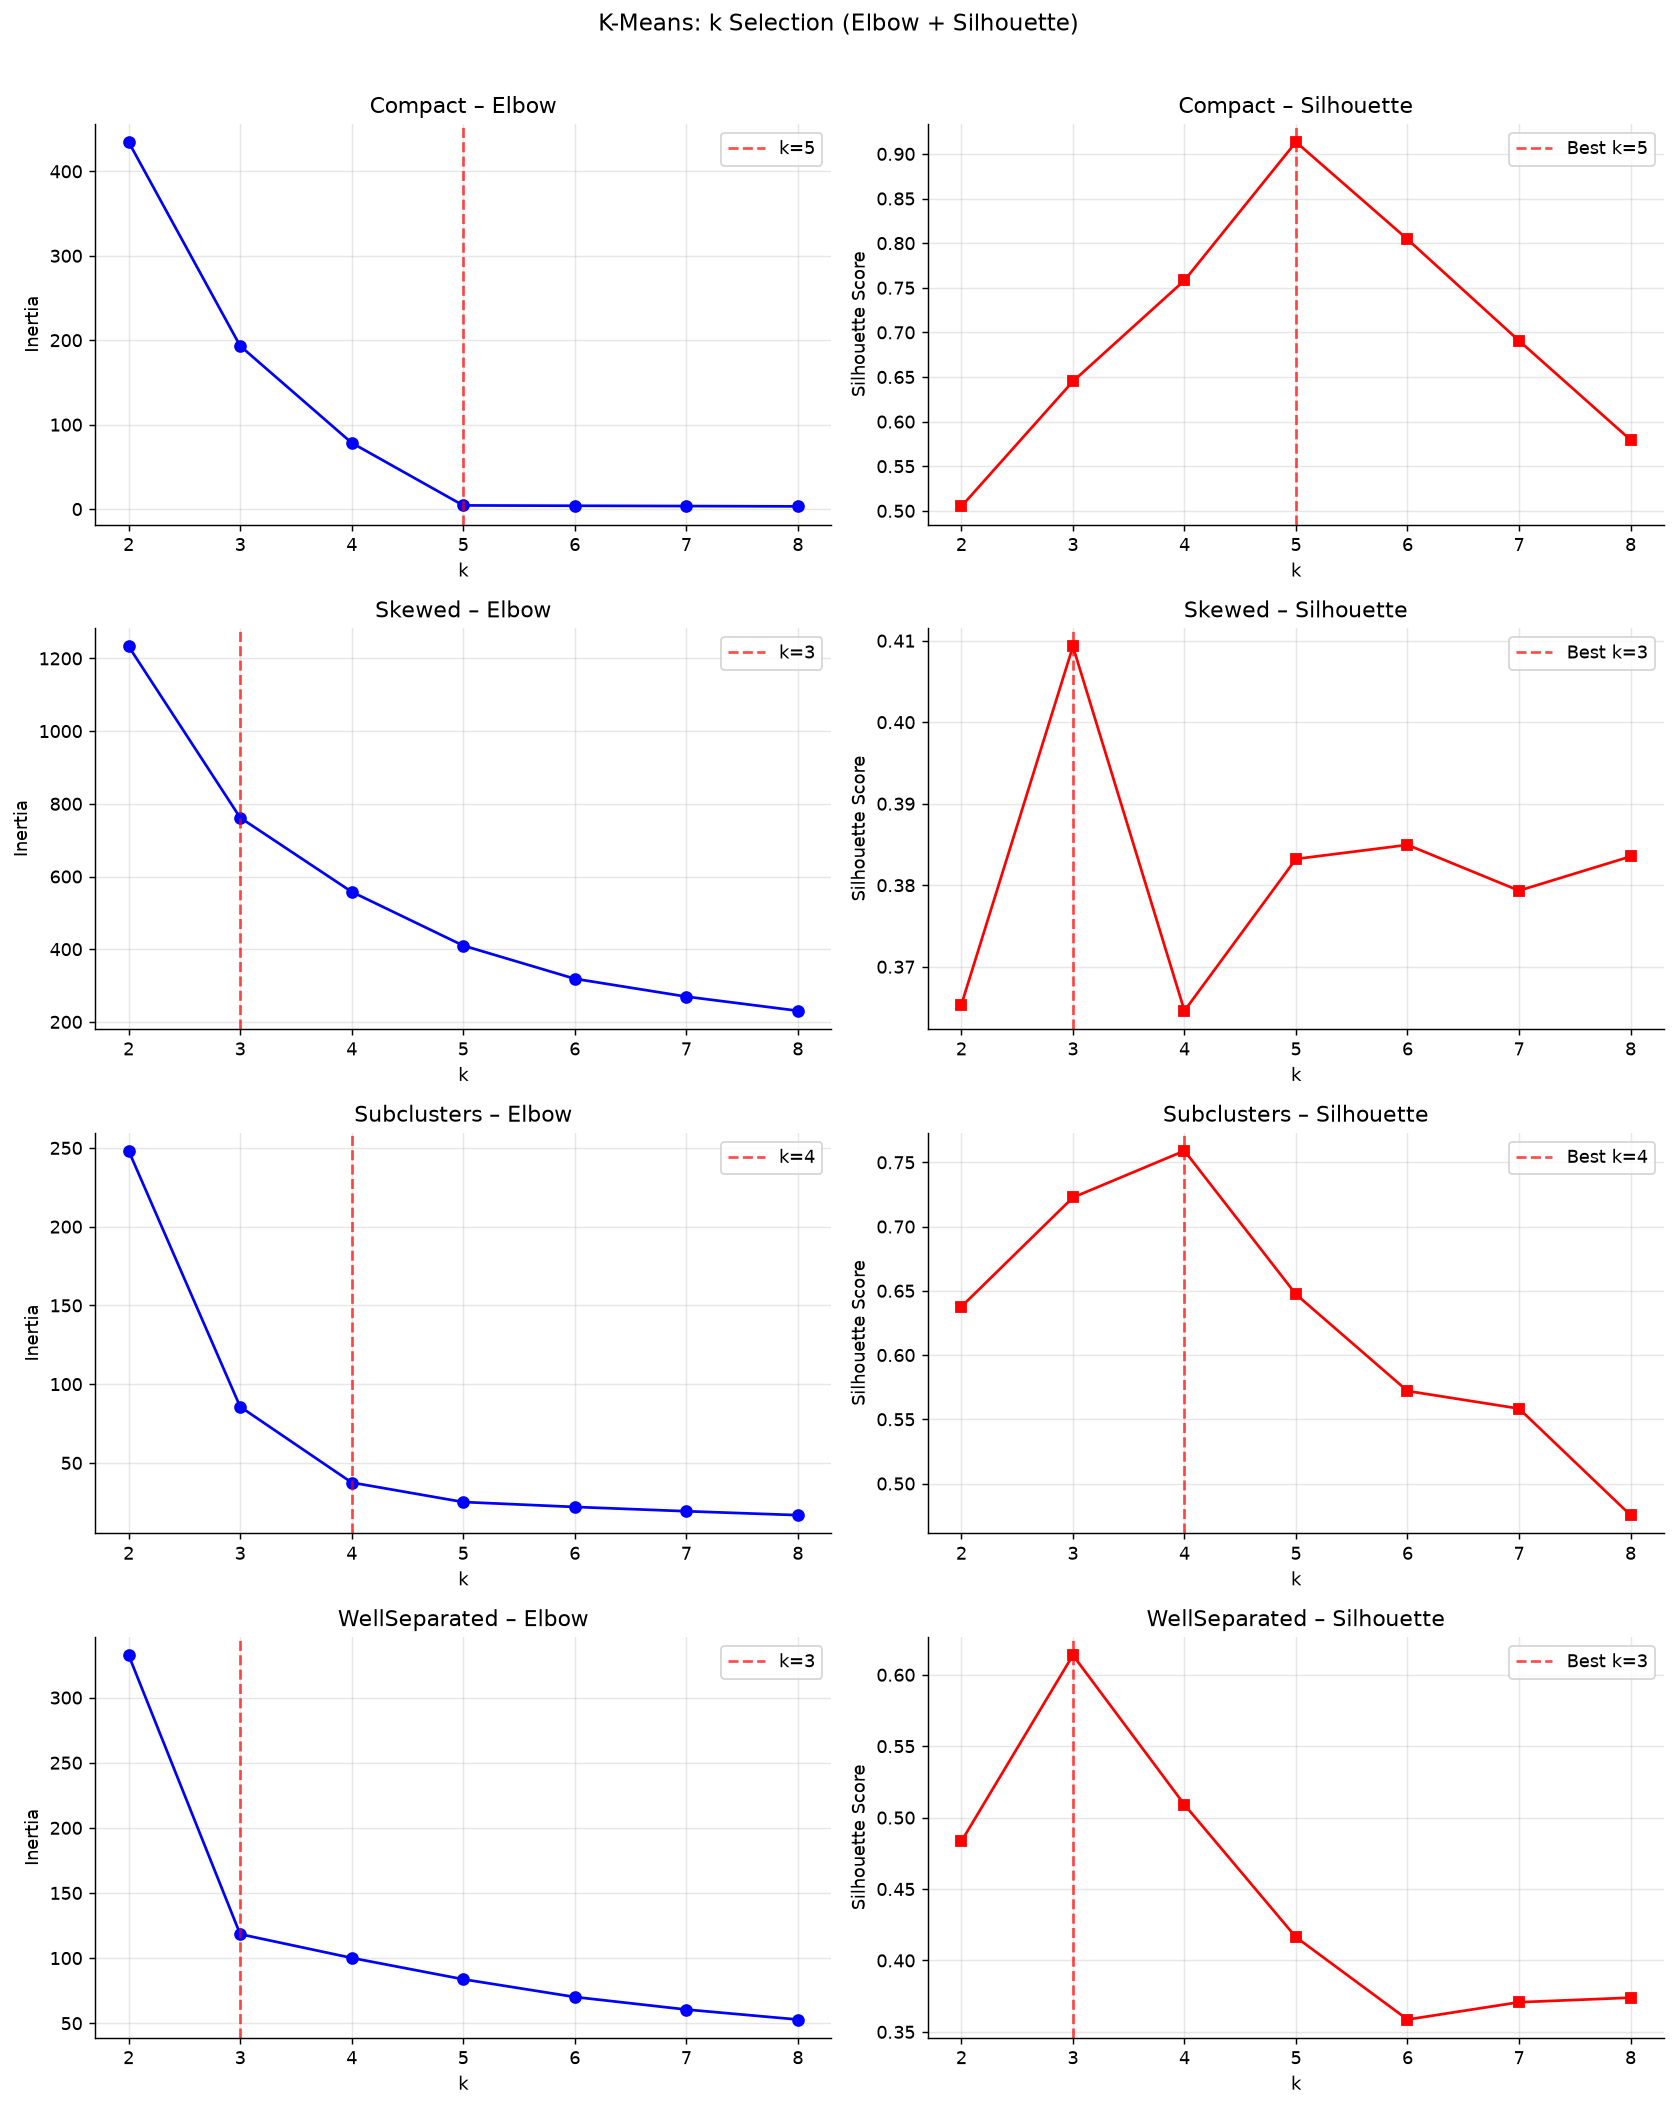

In [4]:
K_RANGE     = range(2, 9)
km_chosen_k = {}   # final chosen k per dataset (by max silhouette)
km_scalers  = {}   # store fitted scalers for centroid back-transform
km_results  = {}   # store labels per dataset

print(f"{'Dataset':>15}  Best-k  Max-Silhouette")
print("-"*42)

fig, axes = plt.subplots(len(datasets), 2, figsize=(13, 4*len(datasets)))

for row_idx, (name, d) in enumerate(datasets.items()):
    sc  = StandardScaler()
    Xs  = sc.fit_transform(d[["x1", "x2"]].values)
    km_scalers[name] = sc

    inertias, sils = [], []
    for k in K_RANGE:
        km_tmp = KMeans(n_clusters=k, init="k-means++", n_init=15, random_state=42)
        km_tmp.fit(Xs)
        inertias.append(km_tmp.inertia_)
        sils.append(silhouette_score(Xs, km_tmp.labels_))

    best_k             = list(K_RANGE)[int(np.argmax(sils))]
    km_chosen_k[name]  = best_k
    print(f"{name:>15}  {best_k:>6}  {max(sils):.4f}")

    # Elbow plot
    axes[row_idx, 0].plot(list(K_RANGE), inertias, "bo-", ms=6)
    axes[row_idx, 0].axvline(x=best_k, color="r", ls="--", alpha=0.7,
                              label=f"k={best_k}")
    axes[row_idx, 0].set(title=f"{name} – Elbow",
                          xlabel="k", ylabel="Inertia")
    axes[row_idx, 0].set_xticks(list(K_RANGE))
    axes[row_idx, 0].grid(alpha=0.3)
    axes[row_idx, 0].legend()

    # Silhouette plot
    axes[row_idx, 1].plot(list(K_RANGE), sils, "rs-", ms=6)
    axes[row_idx, 1].axvline(x=best_k, color="r", ls="--", alpha=0.7,
                              label=f"Best k={best_k}")
    axes[row_idx, 1].set(title=f"{name} – Silhouette",
                          xlabel="k", ylabel="Silhouette Score")
    axes[row_idx, 1].set_xticks(list(K_RANGE))
    axes[row_idx, 1].grid(alpha=0.3)
    axes[row_idx, 1].legend()

plt.suptitle("K-Means: k Selection (Elbow + Silhouette)", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("plots/part3_kmeans_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()


### 3.2 K-Means Cluster Visualisation

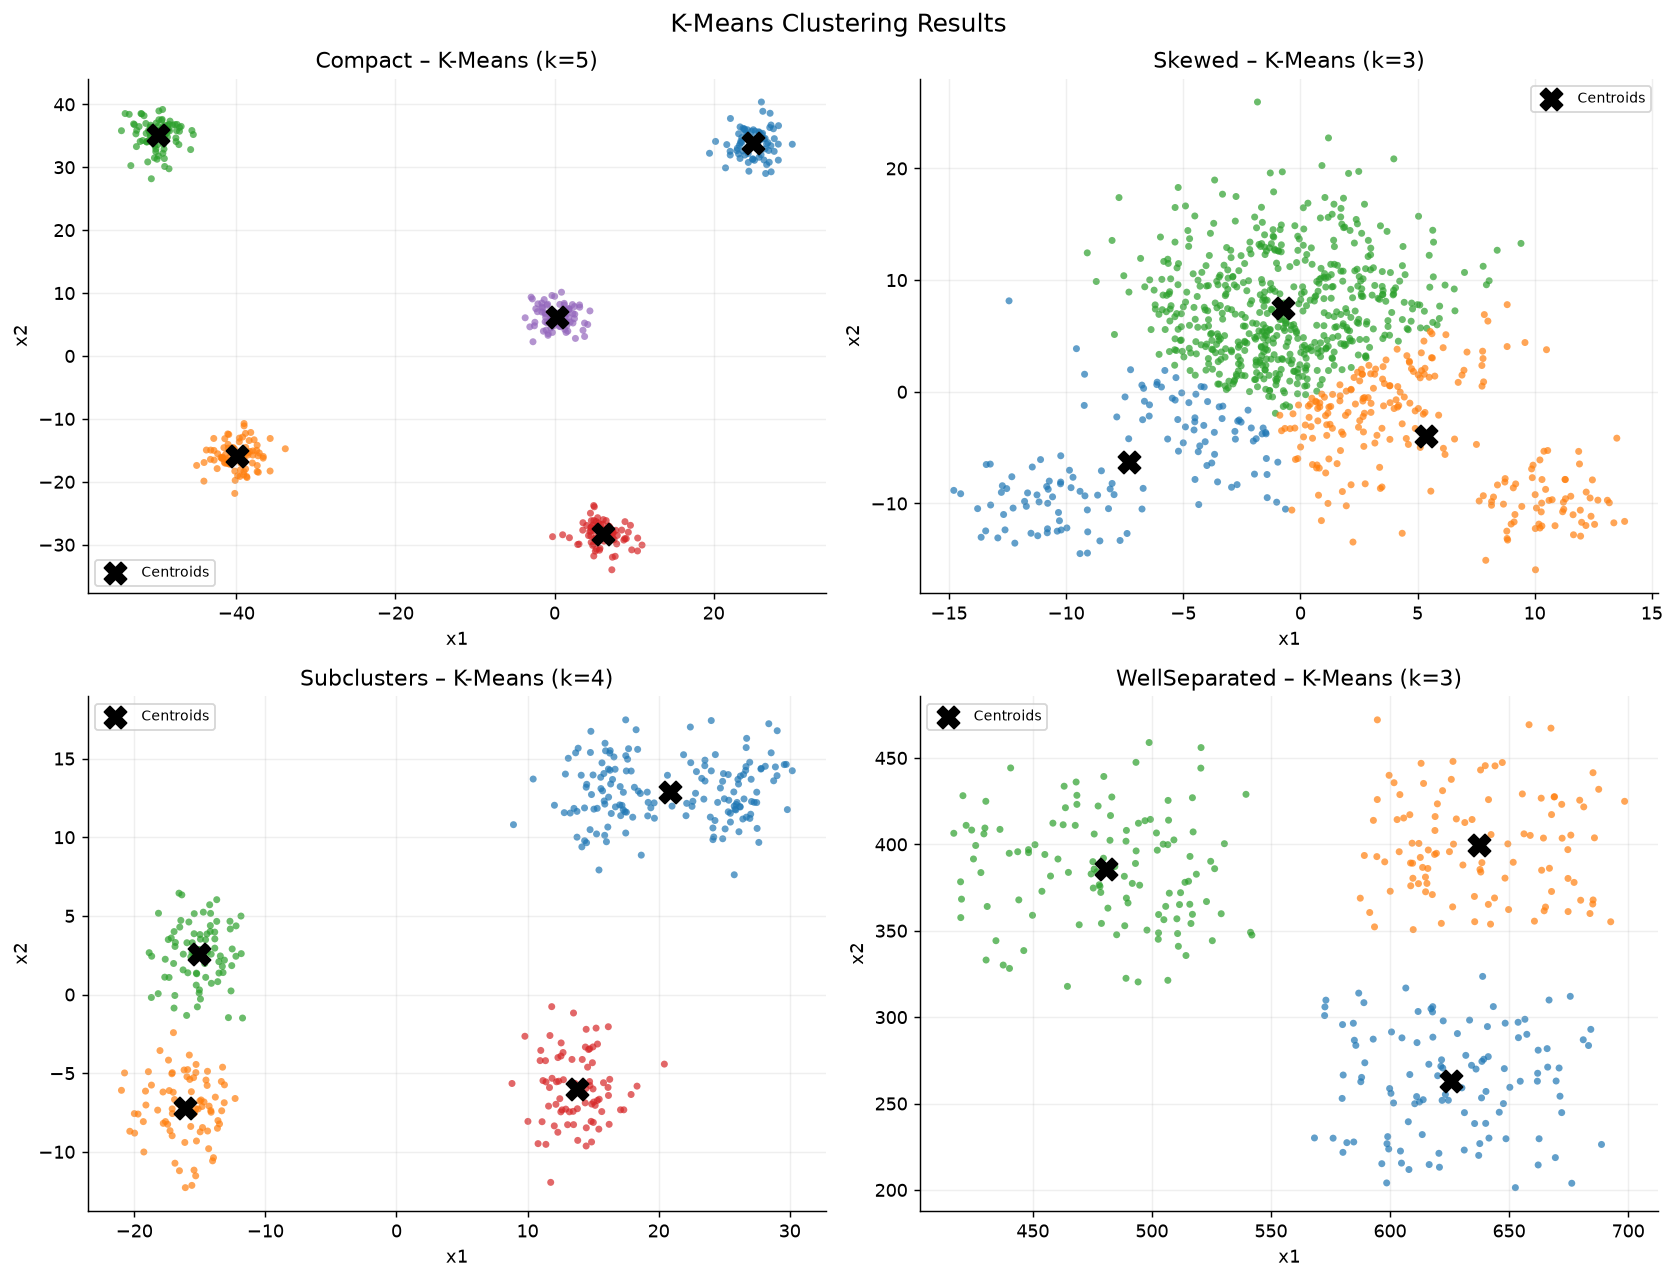

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, (name, d) in zip(axes.flat, datasets.items()):
    sc  = km_scalers[name]
    Xs  = sc.transform(d[["x1", "x2"]].values)
    k   = km_chosen_k[name]
    km  = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=42)
    km.fit(Xs)
    km_results[name] = km.labels_.copy()

    colors = cluster_colors(km.labels_)
    ax.scatter(d.x1, d.x2, c=colors, s=15, alpha=0.7, edgecolors="none")

    # Back-transform centroids to original space using the SAME fitted scaler
    centers_orig = sc.inverse_transform(km.cluster_centers_)
    ax.scatter(centers_orig[:, 0], centers_orig[:, 1],
               c="black", s=150, marker="X", zorder=5, label="Centroids")

    ax.set(title=f"{name} – K-Means (k={k})", xlabel="x1", ylabel="x2")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.suptitle("K-Means Clustering Results", fontsize=14)
plt.tight_layout()
plt.savefig("plots/part3_kmeans_results.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Agglomerative Clustering

### 4.1 All Four Linkages Compared — k chosen independently

For agglomerative clustering, **k is chosen independently of K-Means**: for every dataset and every
linkage we compute the silhouette score for k = 2…10 and take the k with the highest silhouette
(for that linkage). The best linkage per dataset is the one with the highest silhouette at its own k.

| Linkage | Merges by | Bias |
|---|---|---|
| Single | Minimum pairwise distance | Prone to chaining — joins clusters through sparse bridges |
| Complete | Maximum pairwise distance | Forms compact clusters; sensitive to outliers |
| Average | Mean pairwise distance | Compromise between single and complete |
| Ward | Minimises within-cluster variance increase | Same objective as K-Means; prefers spherical, equal-sized clusters |

In [6]:
AGG_K_RANGE  = range(2, 11)
agg_results  = {}   # {dataset: {linkage: labels at chosen k}}
agg_k        = {}   # {dataset: {linkage: chosen k}}
agg_sil_grid = {}   # {dataset: DataFrame k × linkage of silhouettes}
agg_best_lnk = {}   # best linkage per dataset (by silhouette at its own k)

for name, d in datasets.items():
    Xs = km_scalers[name].transform(d[["x1", "x2"]].values)
    grid = pd.DataFrame(index=list(AGG_K_RANGE), columns=LINKAGES, dtype=float)
    labels_by = {}
    for lnk in LINKAGES:
        for k in AGG_K_RANGE:
            lbl = AgglomerativeClustering(n_clusters=k, linkage=lnk).fit_predict(Xs)
            grid.loc[k, lnk] = silhouette_score(Xs, lbl)
            labels_by[(lnk, k)] = lbl
    grid.index.name = "k"
    agg_sil_grid[name] = grid
    agg_k[name]        = {lnk: int(grid[lnk].astype(float).idxmax()) for lnk in LINKAGES}
    agg_results[name]  = {lnk: labels_by[(lnk, agg_k[name][lnk])].copy() for lnk in LINKAGES}
    best_sils          = {lnk: grid.loc[agg_k[name][lnk], lnk] for lnk in LINKAGES}
    agg_best_lnk[name] = max(best_sils, key=best_sils.get)

    print(f"\n=== {name}: silhouette by k (rows) and linkage (columns) ===")
    print(grid.round(3).to_string())

print("\n" + "-" * 52)
print(f"{'Dataset':>15}  {'Linkage':>10}  {'chosen k':>8}  {'Silhouette':>11}")
print("-" * 52)
for name in datasets:
    for lnk in LINKAGES:
        k   = agg_k[name][lnk]
        sil = agg_sil_grid[name].loc[k, lnk]
        best_val = agg_sil_grid[name].loc[agg_k[name][agg_best_lnk[name]], agg_best_lnk[name]]
        n_tied = sum(abs(agg_sil_grid[name].loc[agg_k[name][l], l] - best_val) < 1e-9 for l in LINKAGES)
        is_best = abs(sil - best_val) < 1e-9      # mark only the best (all members of an exact tie)
        flag = ("  ← best" + (" (tied)" if n_tied > 1 else "")) if is_best else ""
        print(f"{name:>15}  {lnk:>10}  {k:>8}  {sil:>11.4f}{flag}")


=== Compact: silhouette by k (rows) and linkage (columns) ===
    single  complete  average   ward
k                                   
2    0.495     0.475    0.495  0.475
3    0.594     0.624    0.624  0.624
4    0.758     0.758    0.758  0.758
5    0.913     0.913    0.913  0.913
6    0.800     0.799    0.808  0.807
7    0.706     0.675    0.713  0.691
8    0.676     0.546    0.614  0.568
9    0.556     0.423    0.581  0.582
10   0.551     0.430    0.479  0.457

=== Skewed: silhouette by k (rows) and linkage (columns) ===
    single  complete  average   ward
k                                   
2    0.321     0.301    0.490  0.490
3    0.266     0.343    0.481  0.487
4    0.224     0.325    0.399  0.308
5    0.282     0.325    0.281  0.335
6    0.133     0.327    0.268  0.348
7    0.124     0.337    0.314  0.342
8    0.243     0.335    0.294  0.353
9    0.194     0.312    0.299  0.359
10   0.192     0.305    0.330  0.355

=== Subclusters: silhouette by k (rows) and linkage (columns

### 4.2 Dendrograms (Ward Linkage — all four datasets), cut at the chosen k

The Ward linkage is computed on **all** points. The red line is drawn at the height that yields
exactly the Ward k chosen above: midway between the (n−k)-th and (n−k+1)-th merge heights.
The dendrogram is truncated to the last 40 merges for readability.

        Compact: Ward k=5, cut height=6.514 (between merge heights 0.856 and 12.173)
         Skewed: Ward k=2, cut height=30.552 (between merge heights 29.781 and 31.323)
    Subclusters: Ward k=4, cut height=7.338 (between merge heights 4.866 and 9.811)
  WellSeparated: Ward k=3, cut height=13.106 (between merge heights 5.466 and 20.747)


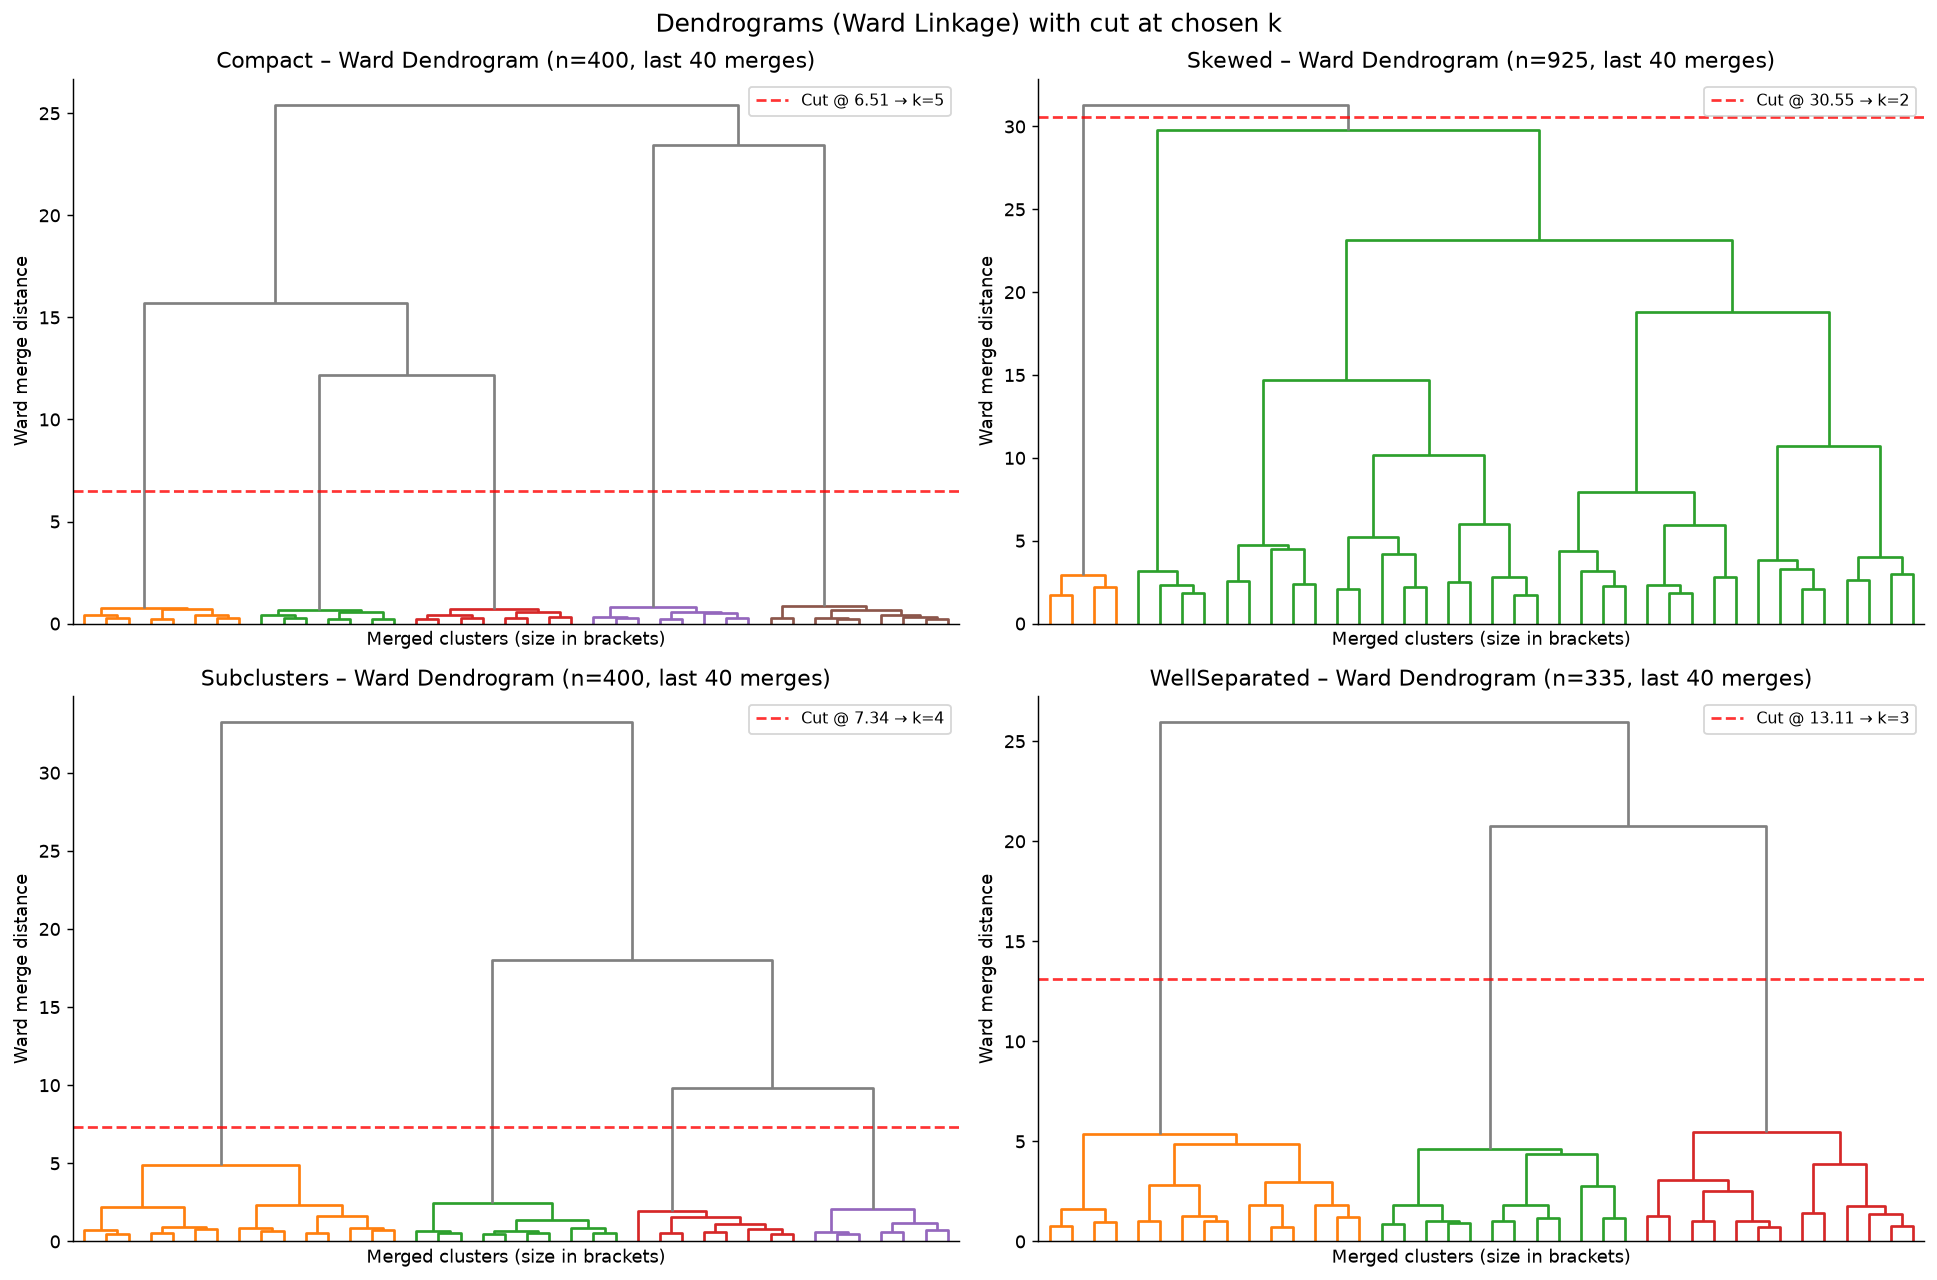

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
from scipy.cluster.hierarchy import fcluster
ward_cut = {}
for ax, (name, d) in zip(axes.flat, datasets.items()):
    Xs = km_scalers[name].transform(d[["x1", "x2"]].values)
    Z  = linkage(Xs, method="ward")
    k  = agg_k[name]["ward"]
    # Merge heights are increasing. To obtain exactly k clusters, the cut
    # must be between the merge that leaves k clusters (Z[-k]) and the next
    # merge that reduces the count to k-1 (Z[-(k-1)]).
    h_lo, h_hi = Z[-k, 2], Z[-(k-1), 2]
    cut = (h_lo + h_hi) / 2
    ward_cut[name] = cut
    assert len(np.unique(fcluster(Z, t=cut, criterion="distance"))) == k
    dendrogram(Z, ax=ax, truncate_mode="lastp", p=40, no_labels=True,
               color_threshold=cut, above_threshold_color="grey")
    ax.axhline(y=cut, color="red", ls="--", alpha=0.8,
               label=f"Cut @ {cut:.2f} → k={k}")
    ax.set(title=f"{name} – Ward Dendrogram (n={len(Xs)}, last 40 merges)",
           xlabel="Merged clusters (size in brackets)", ylabel="Ward merge distance")
    ax.legend(fontsize=9)
    print(f"{name:>15}: Ward k={k}, cut height={cut:.3f} "
          f"(between merge heights {h_lo:.3f} and {h_hi:.3f})")

plt.suptitle("Dendrograms (Ward Linkage) with cut at chosen k", fontsize=14)
plt.tight_layout()
plt.savefig("plots/part3_dendrograms.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the dendrograms (Ward, cut at the chosen k):**
The vertical axis is the Ward merge cost. A good cut lies in a large vertical gap.
- **Compact:** cut at 6.51 for k=5 lies in a huge gap (last within-blob merge 0.86, next merge 12.17) → five unambiguous clusters.
- **WellSeparated:** cut at 13.11 for k=3 lies in a clear gap (5.47 → 20.75).
- **Subclusters:** cut at 7.34 for k=4 (4.87 → 9.81); the merge at 4.87 just below the cut is the
  fusion of the two top-right sub-clusters — a cut below it would give the 5-blob solution.
- **Skewed:** the silhouette-chosen k=2 cut (30.55) sits between merges at 29.78 and 31.32, i.e.
  **no clear gap**: the hierarchy has no well-defined level here, reflecting the unequal sizes/variances.

### 4.3 Agglomerative Cluster Visualisation — All Linkages

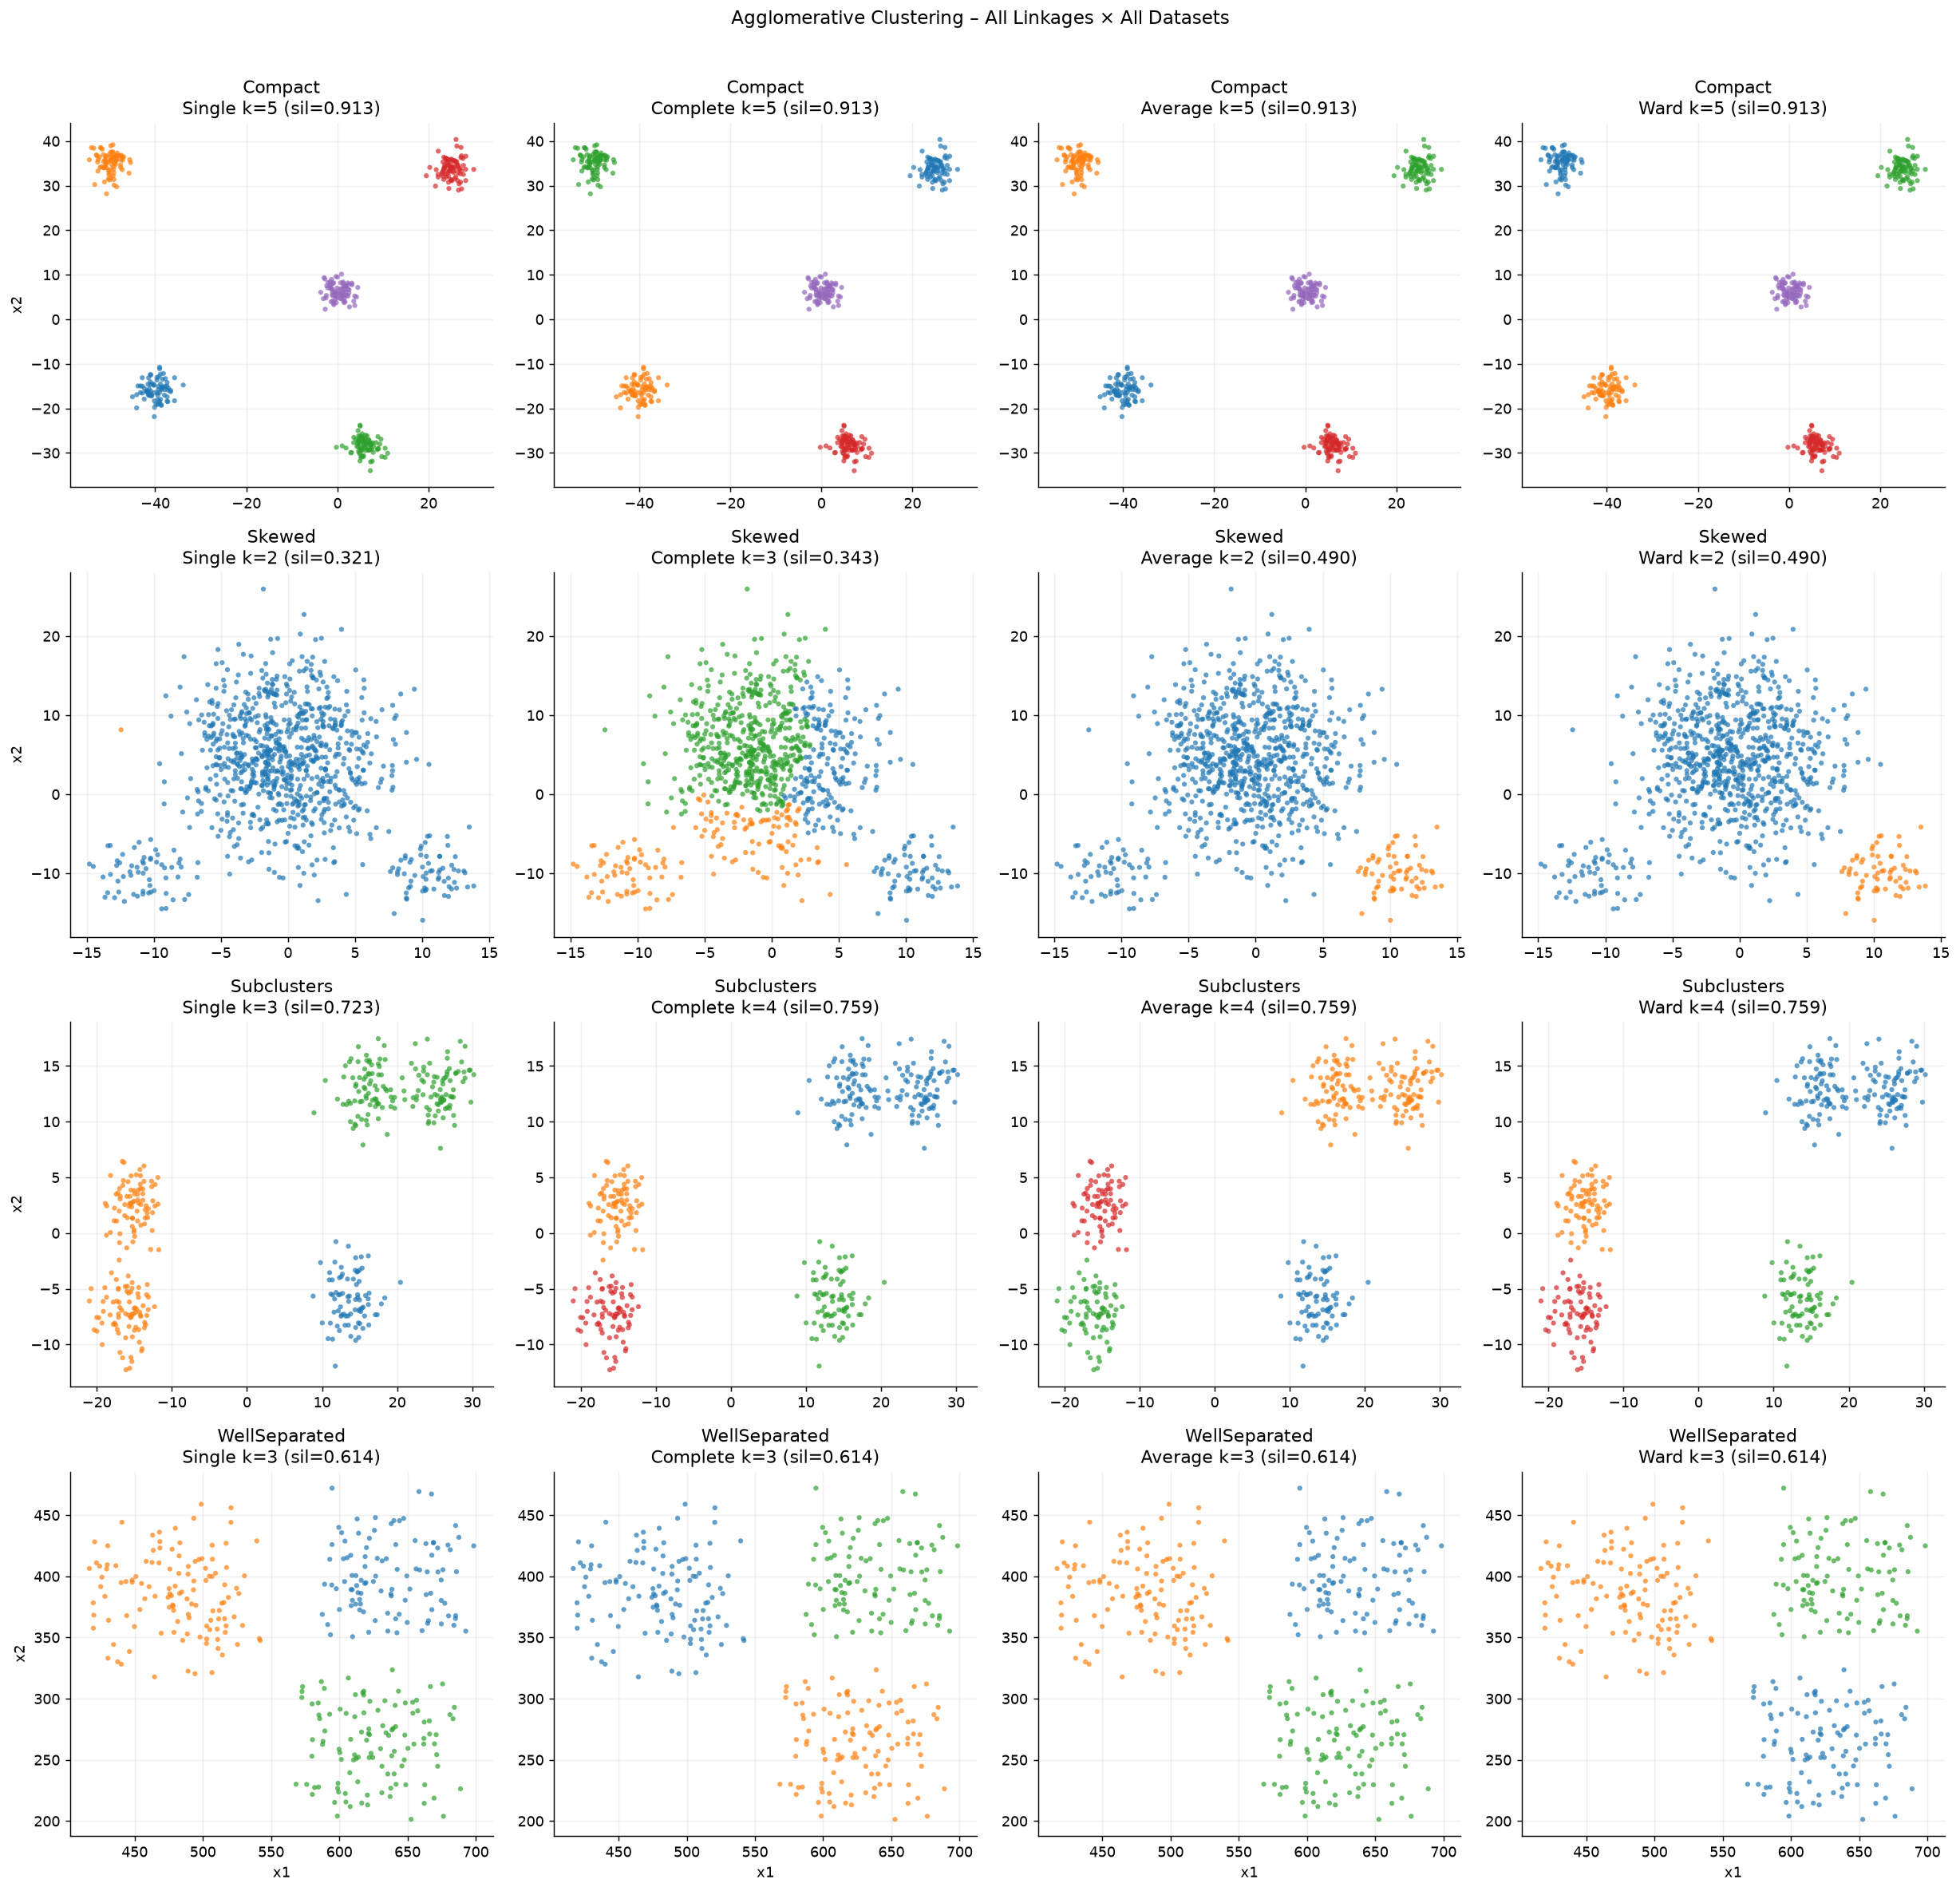

In [8]:
fig, axes = plt.subplots(len(datasets), 4, figsize=(19, 4.5*len(datasets)))

for row_idx, (name, d) in enumerate(datasets.items()):
    Xs = km_scalers[name].transform(d[["x1", "x2"]].values)
    for col_idx, lnk in enumerate(LINKAGES):
        ax  = axes[row_idx, col_idx]
        lbl = agg_results[name][lnk]
        ax.scatter(d.x1, d.x2, c=cluster_colors(lbl), s=12, alpha=0.7,
                   edgecolors="none")
        sil = (silhouette_score(Xs, lbl) if len(set(lbl)) >= 2 else float("nan"))
        ax.set(title=f"{name}\n{lnk.capitalize()} k={agg_k[name][lnk]} (sil={sil:.3f})",
               xlabel="x1" if row_idx == len(datasets)-1 else "",
               ylabel="x2" if col_idx == 0 else "")
        ax.grid(alpha=0.2)

plt.suptitle("Agglomerative Clustering – All Linkages × All Datasets",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("plots/part3_agglomerative_results.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. DBSCAN

### 5.1 Parameter Selection

**`min_samples` choice:** Ester et al. (1996) require `min_samples ≥ D + 1`; the commonly used
default for 2-D data is `min_samples = 2·D = 4` (Ester et al.; Sander et al., 1998). We use
**`min_samples = 4`** for all four datasets: the data are 2-D, contain few obvious outliers, and
the clusters contain 50–600 points each, so a small value is enough to reject isolated points
while not eroding the borders of the smaller/sparser clusters. (Note: in sklearn `min_samples`
counts the point itself, so the matching k-distance is the distance to the 3rd *other* neighbour —
equivalently the 4th column of `NearestNeighbors(n_neighbors=4).kneighbors(X)`, whose first
column is the point itself at distance 0.)

**`eps` from the k-distance plot (k = min_samples = 4):**

1. Compute each point's distance to its fourth nearest neighbour and sort the distances in ascending order.
2. Normalise the distance values to the range [0, 1].
3. Construct a straight line joining the first and last points of the normalised k-distance curve.
4. Calculate the perpendicular distance of each point from this line.
5. Select the point with the maximum perpendicular distance as the stage-1 knee.
6. **Refinement (stage 2):** repeat steps 2–5 on the tail of the curve to the right of the stage-1 knee and use that knee's k-distance as `eps`.

**Why two stages.** On these clean blobs the k-distance curve is long and flat and ends in a very
short, almost vertical spike (a handful of boundary points). Normalised over the whole curve, the
chord heuristic places the knee where the curve *starts* to bend (83–91st percentile), not where it
turns vertical. Using that value (eps = 0.055 / 0.220 / 0.106 / 0.189) labelled 5–10 % of points
as noise on visibly clean blobs and fragmented WellSeparated into 7 and Skewed into 6 clusters,
i.e. eps was clearly too small. Re-applying the same heuristic to the tail locates the actual
elbow (≈ 97–99th percentile), which is the point visual inspection of the plot also suggests.
It remains an estimate; the sensitivity experiment in §5.3 checks it.


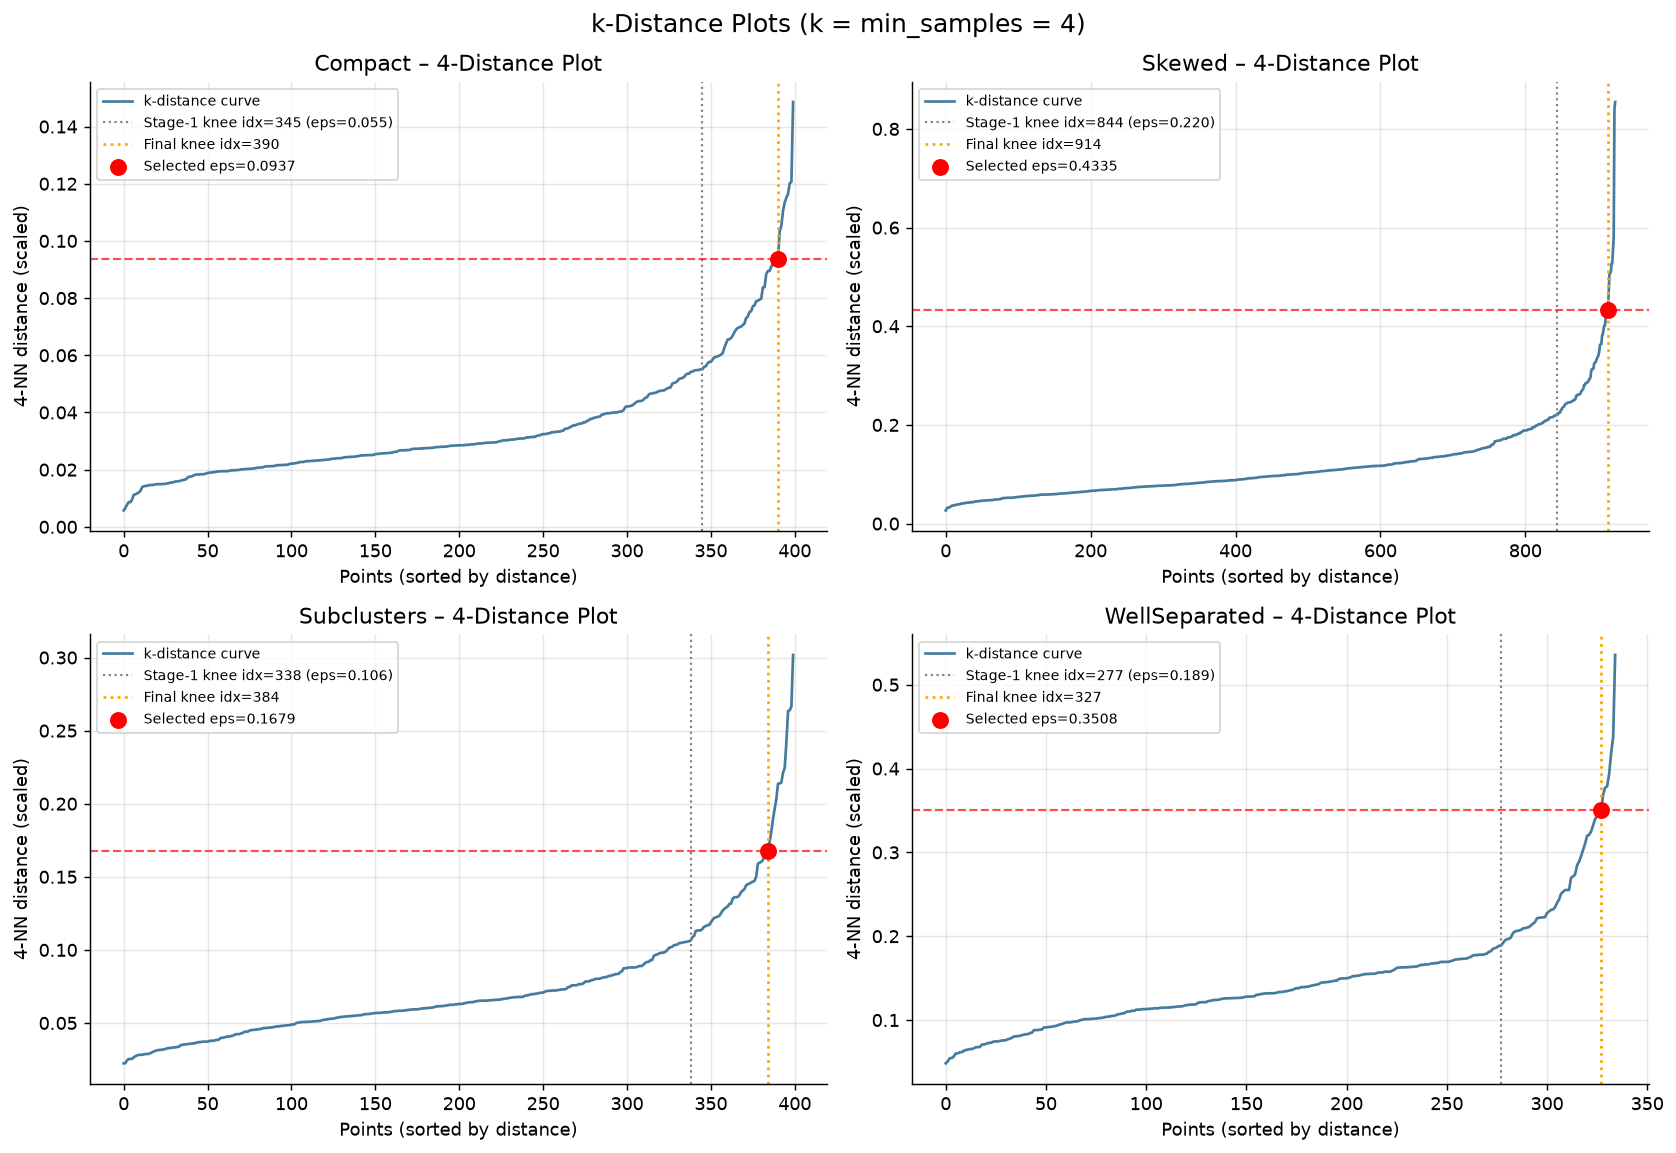

Chosen DBSCAN parameters (min_samples = 4 = 2·D):
          Compact : eps = 0.0937  (knee at 390/400 = 97.5th percentile of k-distances)
           Skewed : eps = 0.4335  (knee at 914/925 = 98.8th percentile of k-distances)
      Subclusters : eps = 0.1679  (knee at 384/400 = 96.0th percentile of k-distances)
    WellSeparated : eps = 0.3508  (knee at 327/335 = 97.6th percentile of k-distances)


In [9]:
MIN_SAMPLES  = 4          # = 2·D for 2-D data
dbscan_eps   = {}          # chosen eps per dataset
dbscan_knees = {}          # knee index for annotation

def estimate_knee(k_distances):
    """
    Estimate the knee of an increasing k-distance curve
    using maximum perpendicular distance from the
    straight line joining its endpoints.
    """
    y = np.asarray(k_distances, dtype=float)

    if len(y) < 3:
        raise ValueError("At least 3 points are required.")

    x = np.linspace(0, 1, len(y))

    x_norm = x
    y_norm = (y - y.min()) / (y.max() - y.min() + 1e-12)

    # Perpendicular distance from the endpoint chord
    x1, y1 = x_norm[0], y_norm[0]
    x2, y2 = x_norm[-1], y_norm[-1]

    distances = np.abs(
        (y2-y1)*x_norm -
        (x2-x1)*y_norm +
        x2*y1 -
        y2*x1
    ) / np.sqrt((y2-y1)**2 + (x2-x1)**2)

    distances[0] = 0
    distances[-1] = 0

    return int(np.argmax(distances))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (name, d) in zip(axes.flat, datasets.items()):
    Xs = km_scalers[name].transform(d[["x1", "x2"]].values)
    dists, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xs).kneighbors(Xs)
    k_dists  = np.sort(dists[:, -1])        # column 0 is the point itself

    # Stage 1: knee of the whole curve (lands at the start of the bend, ~83-91st pct).
    # Stage 2: re-apply the same chord heuristic to the tail k_dists[knee1:], which
    # locates the point where the curve actually turns (near-)vertical.
    knee1    = estimate_knee(k_dists)
    knee_idx = knee1 + estimate_knee(k_dists[knee1:])
    eps_est  = float(k_dists[knee_idx])
    dbscan_eps[name]   = round(eps_est, 4)
    dbscan_knees[name] = knee_idx

    ax.plot(range(len(k_dists)), k_dists, color="#457b9d", lw=1.5, label="k-distance curve")
    ax.axvline(x=knee1, color="grey", ls=":", lw=1.2, label=f"Stage-1 knee idx={knee1} (eps={k_dists[knee1]:.3f})")
    ax.axvline(x=knee_idx, color="orange", ls=":", lw=1.5, label=f"Final knee idx={knee_idx}")
    ax.axhline(y=eps_est, color="red", ls="--", lw=1.2, alpha=0.7)
    ax.scatter(
        knee_idx,
        eps_est,
        color="red",
        s=70,
        zorder=5,
        label=f"Selected eps={eps_est:.4f}"
    )
    ax.set(title=f"{name} – {MIN_SAMPLES}-Distance Plot",
           xlabel="Points (sorted by distance)", ylabel=f"{MIN_SAMPLES}-NN distance (scaled)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle(f"k-Distance Plots (k = min_samples = {MIN_SAMPLES})", fontsize=14)
plt.tight_layout()
plt.savefig("plots/part3_kdistance_plots.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Chosen DBSCAN parameters (min_samples = {MIN_SAMPLES} = 2·D):")
for name, eps in dbscan_eps.items():
    n = len(datasets[name])
    print(f"  {name:>15} : eps = {eps:.4f}  (knee at {dbscan_knees[name]}/{n} = "
          f"{100*dbscan_knees[name]/n:.1f}th percentile of k-distances)")

### 5.2 DBSCAN Clustering Results

DBSCAN Epsilon Validation:
          Compact: eps=0.0937, clusters=5, noise=2 (0.50%)
           Skewed: eps=0.4335, clusters=2, noise=3 (0.32%)
      Subclusters: eps=0.1679, clusters=4, noise=9 (2.25%)
    WellSeparated: eps=0.3508, clusters=3, noise=3 (0.90%)


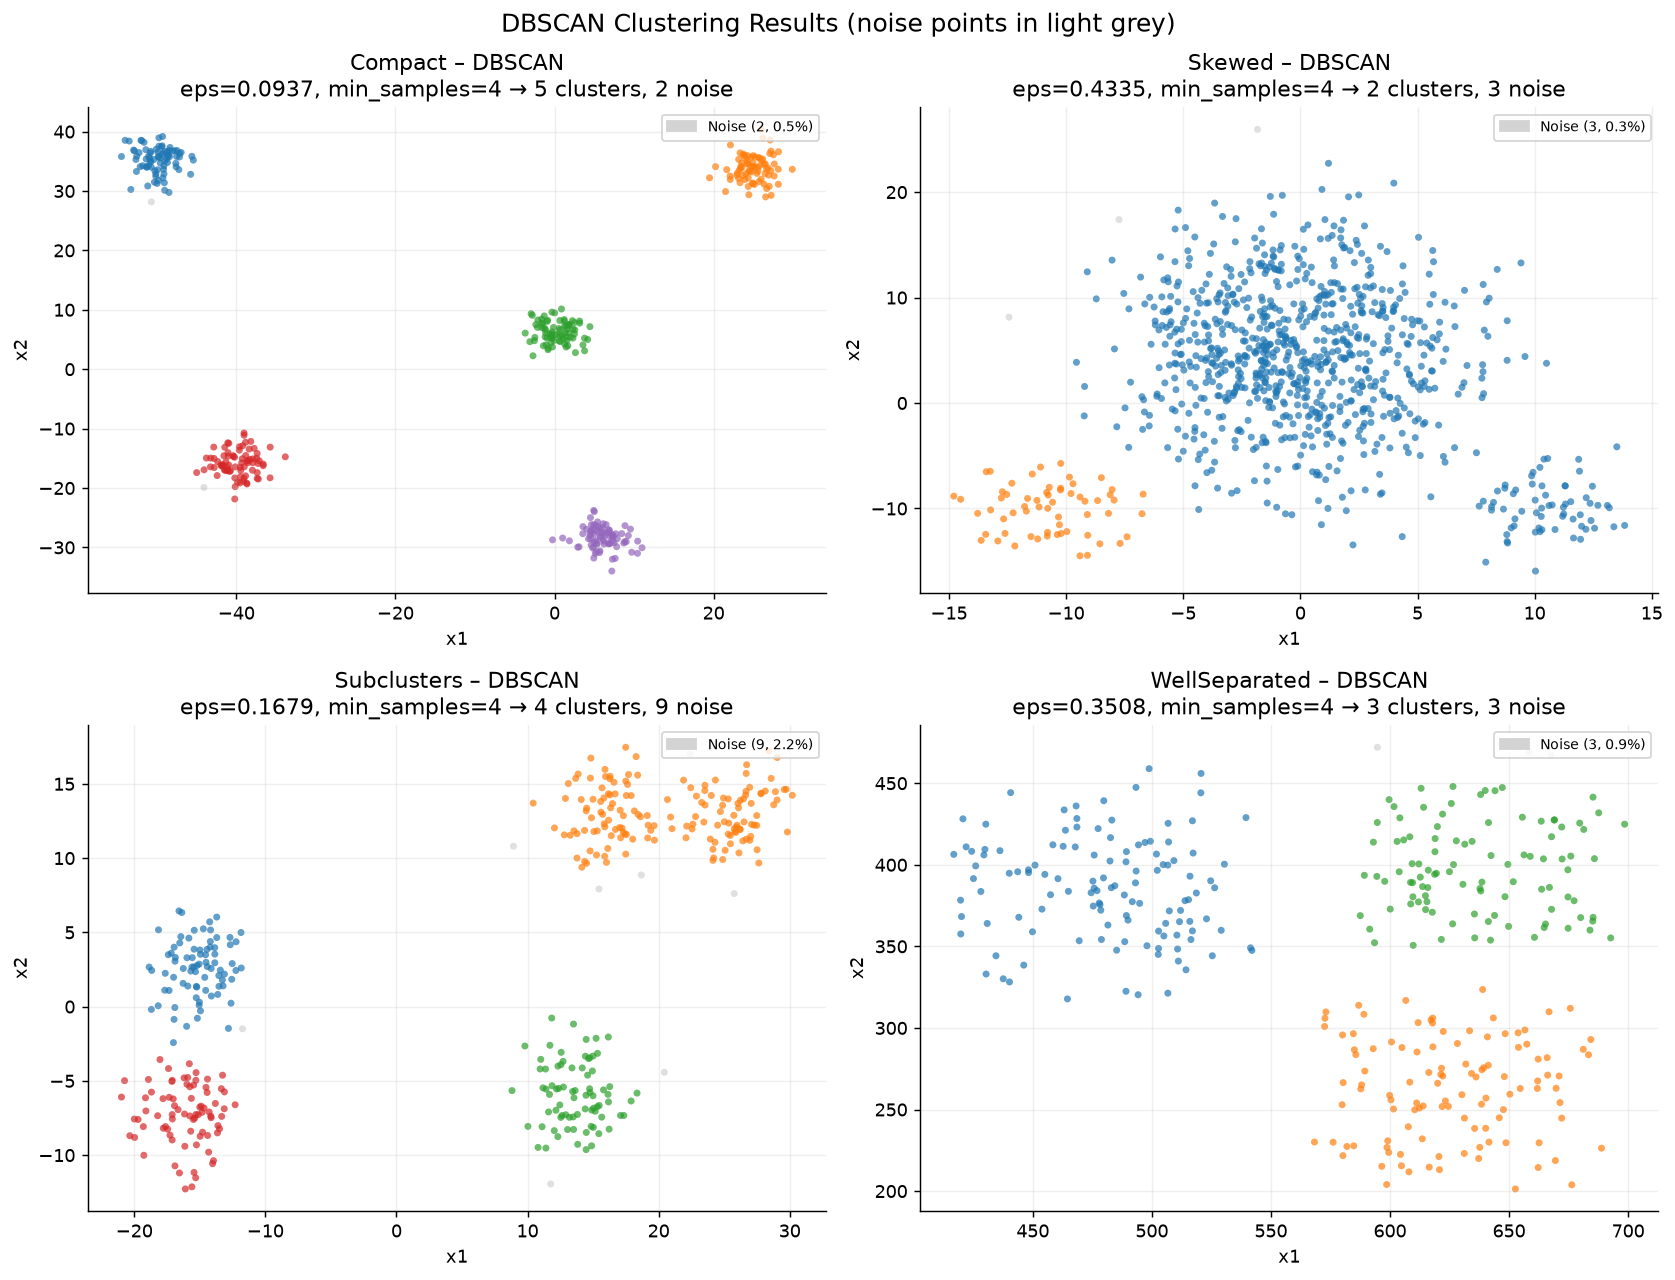

In [10]:
dbscan_results = {}

print("DBSCAN Epsilon Validation:")
for name, d in datasets.items():
    Xs  = km_scalers[name].transform(d[["x1", "x2"]].values)
    eps = dbscan_eps[name]
    db  = DBSCAN(eps=eps, min_samples=MIN_SAMPLES)
    lbl = db.fit_predict(Xs)
    dbscan_results[name] = lbl.copy()

    n_clusters = len(set(lbl) - {-1})
    n_noise    = np.sum(lbl == -1)
    print(
        f"  {name:>15}: eps={eps:.4f}, "
        f"clusters={n_clusters}, "
        f"noise={n_noise} "
        f"({100*n_noise/len(lbl):.2f}%)"
    )

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (name, d) in zip(axes.flat, datasets.items()):
    lbl = dbscan_results[name]
    eps = dbscan_eps[name]
    n_noise    = (lbl == -1).sum()
    n_clusters = len(set(lbl) - {-1})

    ax.scatter(d.x1, d.x2, c=cluster_colors(lbl), s=15, alpha=0.7, edgecolors="none")
    noise_patch = mpatches.Patch(color=NOISE_COLOR,
                                  label=f"Noise ({n_noise}, {100*n_noise/len(lbl):.1f}%)")
    ax.legend(handles=[noise_patch], fontsize=8, loc="upper right")
    ax.set(title=(f"{name} – DBSCAN\n"
                  f"eps={eps:.4f}, min_samples={MIN_SAMPLES} → "
                  f"{n_clusters} clusters, {n_noise} noise"),
           xlabel="x1", ylabel="x2")
    ax.grid(alpha=0.2)

plt.suptitle("DBSCAN Clustering Results (noise points in light grey)", fontsize=14)
plt.tight_layout()
plt.savefig("plots/part3_dbscan_results.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# ── 5.3 DBSCAN Epsilon Sensitivity Experiment ─────────────────────────────────
eps_factors = [0.8, 0.9, 1.0, 1.1, 1.2]

print("DBSCAN Epsilon Sensitivity Analysis (min_samples = 4):")
for name, d in datasets.items():
    Xs = km_scalers[name].transform(d[["x1", "x2"]].values)
    base_eps = dbscan_eps[name]
    print(f"\n{name} (base_eps = {base_eps:.4f}):")
    for factor in eps_factors:
        eps = base_eps * factor
        labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(Xs)
        n_clusters = len(set(labels) - {-1})
        n_noise = np.sum(labels == -1)
        print(
            f"  eps={eps:.4f} ({factor:.1f}x) | "
            f"clusters={n_clusters:>2} | "
            f"noise={n_noise:>3} "
            f"({100*n_noise/len(labels):.2f}%)"
        )

DBSCAN Epsilon Sensitivity Analysis (min_samples = 4):

Compact (base_eps = 0.0937):
  eps=0.0750 (0.8x) | clusters= 5 | noise= 12 (3.00%)
  eps=0.0843 (0.9x) | clusters= 5 | noise=  4 (1.00%)
  eps=0.0937 (1.0x) | clusters= 5 | noise=  2 (0.50%)
  eps=0.1031 (1.1x) | clusters= 5 | noise=  0 (0.00%)
  eps=0.1124 (1.2x) | clusters= 5 | noise=  0 (0.00%)

Skewed (base_eps = 0.4335):
  eps=0.3468 (0.8x) | clusters= 3 | noise= 11 (1.19%)
  eps=0.3901 (0.9x) | clusters= 3 | noise=  6 (0.65%)
  eps=0.4335 (1.0x) | clusters= 2 | noise=  3 (0.32%)
  eps=0.4769 (1.1x) | clusters= 1 | noise=  3 (0.32%)
  eps=0.5202 (1.2x) | clusters= 1 | noise=  2 (0.22%)

Subclusters (base_eps = 0.1679):
  eps=0.1343 (0.8x) | clusters= 4 | noise= 22 (5.50%)
  eps=0.1511 (0.9x) | clusters= 4 | noise= 10 (2.50%)
  eps=0.1679 (1.0x) | clusters= 4 | noise=  9 (2.25%)
  eps=0.1847 (1.1x) | clusters= 3 | noise=  6 (1.50%)
  eps=0.2015 (1.2x) | clusters= 3 | noise=  3 (0.75%)

WellSeparated (base_eps = 0.3508):
  eps=

In [12]:
# ── 6. Parameters used — generated from the variables above ────────────────────
param_rows = []
for name in datasets:
    lbl = dbscan_results[name]
    param_rows.append({
        "Dataset": name,
        "K-Means k": km_chosen_k[name],
        "Agglo k (single/complete/average/ward)": "/".join(str(agg_k[name][l]) for l in LINKAGES),
        "Best linkage": agg_best_lnk[name],
        "Ward cut height": round(ward_cut[name], 2),
        "DBSCAN eps": dbscan_eps[name],
        "DBSCAN min_samples": MIN_SAMPLES,
        "DBSCAN clusters": len(set(lbl) - {-1}),
        "DBSCAN noise %": round(100 * (lbl == -1).mean(), 1),
    })
params_df = pd.DataFrame(param_rows)
md = ["| " + " | ".join(params_df.columns) + " |", "|" + "---|" * len(params_df.columns)]
md += ["| " + " | ".join(str(v) for v in r) + " |" for r in params_df.values]
display(Markdown("## 6. Parameters Used — Summary\n\n" + "\n".join(md)))
print("\n".join(md))

## 6. Parameters Used — Summary

| Dataset | K-Means k | Agglo k (single/complete/average/ward) | Best linkage | Ward cut height | DBSCAN eps | DBSCAN min_samples | DBSCAN clusters | DBSCAN noise % |
|---|---|---|---|---|---|---|---|---|
| Compact | 5 | 5/5/5/5 | single | 6.51 | 0.0937 | 4 | 5 | 0.5 |
| Skewed | 3 | 2/3/2/2 | average | 30.55 | 0.4335 | 4 | 2 | 0.3 |
| Subclusters | 4 | 3/4/4/4 | average | 7.34 | 0.1679 | 4 | 4 | 2.2 |
| WellSeparated | 3 | 3/3/3/3 | single | 13.11 | 0.3508 | 4 | 3 | 0.9 |

| Dataset | K-Means k | Agglo k (single/complete/average/ward) | Best linkage | Ward cut height | DBSCAN eps | DBSCAN min_samples | DBSCAN clusters | DBSCAN noise % |
|---|---|---|---|---|---|---|---|---|
| Compact | 5 | 5/5/5/5 | single | 6.51 | 0.0937 | 4 | 5 | 0.5 |
| Skewed | 3 | 2/3/2/2 | average | 30.55 | 0.4335 | 4 | 2 | 0.3 |
| Subclusters | 4 | 3/4/4/4 | average | 7.34 | 0.1679 | 4 | 4 | 2.2 |
| WellSeparated | 3 | 3/3/3/3 | single | 13.11 | 0.3508 | 4 | 3 | 0.9 |


### 6.1 Parameters Used (static copy of the output above)

| Dataset | K-Means k | Agglo k (single/complete/average/ward) | Best linkage | Ward cut height | DBSCAN eps | DBSCAN min_samples | DBSCAN clusters | DBSCAN noise % |
|---|---|---|---|---|---|---|---|---|
| Compact | 5 | 5/5/5/5 | single | 6.51 | 0.0937 | 4 | 5 | 0.5 |
| Skewed | 3 | 2/3/2/2 | average | 30.55 | 0.4335 | 4 | 2 | 0.3 |
| Subclusters | 4 | 3/4/4/4 | average | 7.34 | 0.1679 | 4 | 4 | 2.2 |
| WellSeparated | 3 | 3/3/3/3 | single | 13.11 | 0.3508 | 4 | 3 | 0.9 |


## 7. Evaluation Metrics Table

In [13]:
rows = []

for name, d in datasets.items():
    Xs = km_scalers[name].transform(d[["x1", "x2"]].values)
    k  = km_chosen_k[name]

    # K-Means
    sc = compute_scores(Xs, km_results[name])
    rows.append({"Dataset": name, "Algorithm": f"K-Means (k={k})", **sc})

    # Agglomerative — all four linkages (no duplicates)
    for lnk in LINKAGES:
        lbl = agg_results[name][lnk]
        sc  = compute_scores(Xs, lbl)
        rows.append({"Dataset": name,
                     "Algorithm": f"Agglo-{lnk.capitalize()} (k={agg_k[name][lnk]})", **sc})

    # DBSCAN
    sc = compute_scores(Xs, dbscan_results[name])
    rows.append({"Dataset": name,
                 "Algorithm": f"DBSCAN (eps={dbscan_eps[name]}, min_s={MIN_SAMPLES})",
                 **sc})

results_df = pd.DataFrame(rows)
for col in ["silhouette","davies_bouldin"]:
    results_df[col] = results_df[col].round(4)
results_df["calinski_harabasz"] = results_df["calinski_harabasz"].round(2)
results_df["pct_noise"]         = results_df["pct_noise"].round(2)

print(f"Total rows in results table: {len(results_df)}")
print(f"Algorithms per dataset: {len(rows)//len(datasets)}")
print()
# Print raw DataFrame for quick inspection
display(results_df)

Total rows in results table: 24
Algorithms per dataset: 6



,Dataset,Algorithm,silhouette,davies_bouldin,calinski_harabasz,n_noise,pct_noise,n_clusters
0,Compact,K-Means (k=5),0.9133,0.1183,18056.99,0,0.00,5
1,Compact,Agglo-Single (k=5),0.9133,0.1183,18056.99,0,0.00,5
2,Compact,Agglo-Complete (k=5),0.9133,0.1183,18056.99,0,0.00,5
3,Compact,Agglo-Average (k=5),0.9133,0.1183,18056.99,0,0.00,5
4,Compact,Agglo-Ward (k=5),0.9133,0.1183,18056.99,0,0.00,5
5,Compact,"DBSCAN (eps=0.0937, min_s=4)",0.9139,0.1178,18368.03,2,0.50,5
6,Skewed,K-Means (k=3),0.4093,0.8573,658.43,0,0.00,3
7,Skewed,Agglo-Single (k=2),0.3206,0.4837,3.06,0,0.00,2
8,Skewed,Agglo-Complete (k=3),0.3434,1.0155,484.94,0,0.00,3
9,Skewed,Agglo-Average (k=2),0.4897,0.5111,333.09,0,0.00,2


In [14]:
# ── Render as a proper Markdown table inside the notebook ─────────────────────
def _fmt(v, kind="f4"):
    if isinstance(v, float) and np.isnan(v): return "N/A"
    if kind == "f4": return f"{v:.4f}"
    if kind == "f2": return f"{v:.2f}"
    return str(v)

hdr  = ("| Dataset | Algorithm | k / params | Silhouette ↑ | "
        "Davies-Bouldin ↓ | Calinski-Harabász ↑ | # Noise | % Noise |")
sep  = "|---|---|---|---|---|---|---|---|"
lines = [hdr, sep]

for _, row in results_df.iterrows():
    # Extract k or eps from algorithm string for the params column
    algo   = row["Algorithm"]
    nn     = str(int(row["n_noise"]))
    pn     = f"{row['pct_noise']:.1f}%"
    sil    = _fmt(row["silhouette"])
    db     = _fmt(row["davies_bouldin"])
    ch     = _fmt(row["calinski_harabasz"], "f2")
    n_cl   = str(int(row["n_clusters"])) if not np.isnan(row["n_clusters"]) else "?"
    sub = results_df[results_df["Dataset"] == row["Dataset"]]
    if row["silhouette"] == sub["silhouette"].max(): sil = f"**{sil}**"
    if row["davies_bouldin"] == sub["davies_bouldin"].min(): db = f"**{db}**"
    if row["calinski_harabasz"] == sub["calinski_harabasz"].max(): ch = f"**{ch}**"
    lines.append(f"| {row['Dataset']} | {algo} | {n_cl} clusters | "
                 f"{sil} | {db} | {ch} | {nn} | {pn} |")

md_table = "\n".join(lines)
display(Markdown(md_table))
print("Bold = best value of that metric within the dataset.")
print("\n↑ Table rendered as Markdown above (and also printed below for copy-paste):")
print(md_table)

| Dataset | Algorithm | k / params | Silhouette ↑ | Davies-Bouldin ↓ | Calinski-Harabász ↑ | # Noise | % Noise |
|---|---|---|---|---|---|---|---|
| Compact | K-Means (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | Agglo-Single (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | Agglo-Complete (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | Agglo-Average (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | Agglo-Ward (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | DBSCAN (eps=0.0937, min_s=4) | 5 clusters | **0.9139** | **0.1178** | **18368.03** | 2 | 0.5% |
| Skewed | K-Means (k=3) | 3 clusters | 0.4093 | 0.8573 | **658.43** | 0 | 0.0% |
| Skewed | Agglo-Single (k=2) | 2 clusters | 0.3206 | **0.4837** | 3.06 | 0 | 0.0% |
| Skewed | Agglo-Complete (k=3) | 3 clusters | 0.3434 | 1.0155 | 484.94 | 0 | 0.0% |
| Skewed | Agglo-Average (k=2) | 2 clusters | **0.4897** | 0.5111 | 333.09 | 0 | 0.0% |
| Skewed | Agglo-Ward (k=2) | 2 clusters | **0.4897** | 0.5111 | 333.09 | 0 | 0.0% |
| Skewed | DBSCAN (eps=0.4335, min_s=4) | 2 clusters | 0.4870 | 0.5358 | 302.94 | 3 | 0.3% |
| Subclusters | K-Means (k=4) | 4 clusters | 0.7590 | 0.3281 | 2682.15 | 0 | 0.0% |
| Subclusters | Agglo-Single (k=3) | 3 clusters | 0.7226 | 0.4174 | 1655.44 | 0 | 0.0% |
| Subclusters | Agglo-Complete (k=4) | 4 clusters | 0.7587 | 0.3287 | 2679.99 | 0 | 0.0% |
| Subclusters | Agglo-Average (k=4) | 4 clusters | 0.7590 | 0.3281 | 2682.15 | 0 | 0.0% |
| Subclusters | Agglo-Ward (k=4) | 4 clusters | 0.7590 | 0.3281 | 2682.15 | 0 | 0.0% |
| Subclusters | DBSCAN (eps=0.1679, min_s=4) | 4 clusters | **0.7648** | **0.3220** | **2791.81** | 9 | 2.2% |
| WellSeparated | K-Means (k=3) | 3 clusters | 0.6137 | 0.5374 | 773.67 | 0 | 0.0% |
| WellSeparated | Agglo-Single (k=3) | 3 clusters | 0.6137 | 0.5374 | 773.67 | 0 | 0.0% |
| WellSeparated | Agglo-Complete (k=3) | 3 clusters | 0.6137 | 0.5374 | 773.67 | 0 | 0.0% |
| WellSeparated | Agglo-Average (k=3) | 3 clusters | 0.6137 | 0.5374 | 773.67 | 0 | 0.0% |
| WellSeparated | Agglo-Ward (k=3) | 3 clusters | 0.6137 | 0.5374 | 773.67 | 0 | 0.0% |
| WellSeparated | DBSCAN (eps=0.3508, min_s=4) | 3 clusters | **0.6148** | **0.5313** | **780.34** | 3 | 0.9% |

Bold = best value of that metric within the dataset.

↑ Table rendered as Markdown above (and also printed below for copy-paste):
| Dataset | Algorithm | k / params | Silhouette ↑ | Davies-Bouldin ↓ | Calinski-Harabász ↑ | # Noise | % Noise |
|---|---|---|---|---|---|---|---|
| Compact | K-Means (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | Agglo-Single (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | Agglo-Complete (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | Agglo-Average (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | Agglo-Ward (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | DBSCAN (eps=0.0937, min_s=4) | 5 clusters | **0.9139** | **0.1178** | **18368.03** | 2 | 0.5% |
| Skewed | K-Means (k=3) | 3 clusters | 0.4093 | 0.8573 | **658.43** | 0 | 0.0% |
| Skewed | Agglo-Single (k=2) | 2 clusters | 0.3206 | **0.4837** | 3.06 | 0 | 0.0% |
| Skewed | Agglo-Compl

### 7.1 Final Score Table (static copy of the output above)

Bold = best value of that metric within the dataset. DBSCAN scores exclude noise points.

| Dataset | Algorithm | k / params | Silhouette ↑ | Davies-Bouldin ↓ | Calinski-Harabász ↑ | # Noise | % Noise |
|---|---|---|---|---|---|---|---|
| Compact | K-Means (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | Agglo-Single (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | Agglo-Complete (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | Agglo-Average (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | Agglo-Ward (k=5) | 5 clusters | 0.9133 | 0.1183 | 18056.99 | 0 | 0.0% |
| Compact | DBSCAN (eps=0.0937, min_s=4) | 5 clusters | **0.9139** | **0.1178** | **18368.03** | 2 | 0.5% |
| Skewed | K-Means (k=3) | 3 clusters | 0.4093 | 0.8573 | **658.43** | 0 | 0.0% |
| Skewed | Agglo-Single (k=2) | 2 clusters | 0.3206 | **0.4837** | 3.06 | 0 | 0.0% |
| Skewed | Agglo-Complete (k=3) | 3 clusters | 0.3434 | 1.0155 | 484.94 | 0 | 0.0% |
| Skewed | Agglo-Average (k=2) | 2 clusters | **0.4897** | 0.5111 | 333.09 | 0 | 0.0% |
| Skewed | Agglo-Ward (k=2) | 2 clusters | **0.4897** | 0.5111 | 333.09 | 0 | 0.0% |
| Skewed | DBSCAN (eps=0.4335, min_s=4) | 2 clusters | 0.4870 | 0.5358 | 302.94 | 3 | 0.3% |
| Subclusters | K-Means (k=4) | 4 clusters | 0.7590 | 0.3281 | 2682.15 | 0 | 0.0% |
| Subclusters | Agglo-Single (k=3) | 3 clusters | 0.7226 | 0.4174 | 1655.44 | 0 | 0.0% |
| Subclusters | Agglo-Complete (k=4) | 4 clusters | 0.7587 | 0.3287 | 2679.99 | 0 | 0.0% |
| Subclusters | Agglo-Average (k=4) | 4 clusters | 0.7590 | 0.3281 | 2682.15 | 0 | 0.0% |
| Subclusters | Agglo-Ward (k=4) | 4 clusters | 0.7590 | 0.3281 | 2682.15 | 0 | 0.0% |
| Subclusters | DBSCAN (eps=0.1679, min_s=4) | 4 clusters | **0.7648** | **0.3220** | **2791.81** | 9 | 2.2% |
| WellSeparated | K-Means (k=3) | 3 clusters | 0.6137 | 0.5374 | 773.67 | 0 | 0.0% |
| WellSeparated | Agglo-Single (k=3) | 3 clusters | 0.6137 | 0.5374 | 773.67 | 0 | 0.0% |
| WellSeparated | Agglo-Complete (k=3) | 3 clusters | 0.6137 | 0.5374 | 773.67 | 0 | 0.0% |
| WellSeparated | Agglo-Average (k=3) | 3 clusters | 0.6137 | 0.5374 | 773.67 | 0 | 0.0% |
| WellSeparated | Agglo-Ward (k=3) | 3 clusters | 0.6137 | 0.5374 | 773.67 | 0 | 0.0% |
| WellSeparated | DBSCAN (eps=0.3508, min_s=4) | 3 clusters | **0.6148** | **0.5313** | **780.34** | 3 | 0.9% |


**Metric interpretation:**
- **Silhouette score (↑ higher is better):** Ranges [−1, 1]. Measures how similar each point
  is to its own cluster vs the nearest other cluster. 1 = perfectly separated, 0 = on boundary,
  < 0 = likely misassigned.
- **Davies–Bouldin index (↓ lower is better):** Average similarity between each cluster and its
  most similar other cluster. 0 = perfect separation.
- **Calinski–Harabász (↑ higher is better):** Ratio of between-cluster variance to
  within-cluster variance. Higher → more compact and well-separated clusters.
- **# Noise / % Noise:** DBSCAN only. Scores are computed *excluding* noise points (required),
  so these columns must always be reported alongside DBSCAN scores.


## 8. Analysis and Discussion

In [15]:
# ── Per-dataset best by each metric (noise-aware: DBSCAN scores exclude noise) ─
for name in datasets:
    sub = results_df[results_df["Dataset"] == name].dropna(subset=["silhouette"])
    b_s = sub.loc[sub["silhouette"].idxmax()]
    b_d = sub.loc[sub["davies_bouldin"].idxmin()]
    b_c = sub.loc[sub["calinski_harabasz"].idxmax()]
    print(f"{name:>15}: best silhouette {b_s['Algorithm']} ({b_s['silhouette']:.4f}) | "
          f"best DB {b_d['Algorithm']} ({b_d['davies_bouldin']:.4f}) | "
          f"best CH {b_c['Algorithm']} ({b_c['calinski_harabasz']:.1f})")

        Compact: best silhouette DBSCAN (eps=0.0937, min_s=4) (0.9139) | best DB DBSCAN (eps=0.0937, min_s=4) (0.1178) | best CH DBSCAN (eps=0.0937, min_s=4) (18368.0)
         Skewed: best silhouette Agglo-Average (k=2) (0.4897) | best DB Agglo-Single (k=2) (0.4837) | best CH K-Means (k=3) (658.4)
    Subclusters: best silhouette DBSCAN (eps=0.1679, min_s=4) (0.7648) | best DB DBSCAN (eps=0.1679, min_s=4) (0.3220) | best CH DBSCAN (eps=0.1679, min_s=4) (2791.8)
  WellSeparated: best silhouette DBSCAN (eps=0.3508, min_s=4) (0.6148) | best DB DBSCAN (eps=0.3508, min_s=4) (0.5313) | best CH DBSCAN (eps=0.3508, min_s=4) (780.3)


### 8.1 Which Algorithm Performs Best for Each Dataset?

*(Numbers from the static table in §7 and the scatter plots above. DBSCAN scores exclude noise.)*

| Dataset | Best | Evidence |
|---|---|---|
| **Compact** | **All methods tie** (K-Means, all 4 linkages, DBSCAN) | All find the 5 blobs (80 points each). K-Means / all linkages: sil 0.9133, DB 0.1183, CH 18,057. DBSCAN (eps=0.0937) finds the same 5 blobs and only marks 2 boundary points (0.5 %) as noise; its marginally higher scores (0.9139 / 0.1178 / 18,368) come solely from dropping those 2 points. |
| **WellSeparated** | **All methods tie** (K-Means, all 4 linkages, DBSCAN) | The 3 clusters are recovered identically by K-Means and every linkage (sil 0.6137, DB 0.5374, CH 773.7). DBSCAN (eps=0.3508) finds the same 3 clusters with 3 noise points (0.9 %), scoring 0.6148 / 0.5313 / 780.3 — again only because the 3 outermost points are excluded. |
| **Subclusters** | **K-Means = Average = Ward (k=4)**, DBSCAN equivalent | K-Means, Average and Ward find the 4 main groups (the two touching top-right sub-clusters are merged): sil 0.7590, DB 0.3281, CH 2,682; Complete is practically identical (0.7587). DBSCAN (eps=0.1679) gives the same 4 groups with 9 noise points (2.2 %) → 0.7648 / 0.3220 / 2,792. Single linkage (k=3) is worst (0.7226): it chains the two left groups. No method separates the 5 fine-level blobs at its chosen parameters. |
| **Skewed** | **No method recovers all 3 groups at its chosen parameters; Average / Ward (k=2) best by silhouette (0.4897), DBSCAN (k=2, sil 0.4870) practically tied** | Average/Ward isolate the **bottom-right** group but merge the bottom-left group into the large cloud. DBSCAN (eps=0.4335) does the mirror image: it isolates the **bottom-left** group but the bottom-right group is density-connected to the cloud and merged (3 noise points, 0.3 %). The sensitivity run (§5.3) shows that a slightly smaller eps (0.9× = 0.390, 0.8× = 0.347) makes DBSCAN recover **all three real groups** with only 6–11 noise points (0.7–1.2 %), so DBSCAN is the only method that *can* separate the structure — but the result hinges on eps. K-Means (k=3, best CH 658.4) has the right k but slices the large cloud: each small group is attached to a wedge of the cloud. Complete (k=3) cuts the cloud too (worst DB 1.0155). Single linkage's low DB (0.4837) is an artefact: its second "cluster" is one isolated point (CH 3.06). |

### 8.2 Where and Why Each Algorithm Fails (by assumption)

**K-Means — shape, size and variance.** K-Means assumes convex, isotropic clusters of similar
size and variance (Voronoi cells around centroids). On *Skewed* this is violated: with k=3 the
centroids are placed to minimise squared error, so the large high-variance cloud is split into
three wedges and each small group is attached to a wedge of the big cloud (see the K-Means plot).
On *Compact*, *WellSeparated* and the coarse level of *Subclusters* the assumptions hold, so it
works reliably.

**Single linkage — chaining.** It merges via the closest pair of points, so a thin bridge suffices.
On *Skewed* the dense continuum joins everything into one cluster and the only "split" at k=2 is a
single isolated point (CH = 3.06). On *Subclusters* (k=3) it chains the two left groups together.
It only works well when inter-cluster gaps are large (*Compact*, *WellSeparated*).

**Complete linkage — size/variance.** Uses the maximum distance, so it prefers clusters of
similar diameter: on *Skewed* (k=3) it cuts the large cloud in two and joins its lower part with
the bottom-left group (worst DB, 1.0155).

**Average / Ward — size and variance.** Ward has the same variance-minimising objective as K-Means.
On *Skewed*, splitting off one small, distant group costs less than separating the second small
group (which lies close to the large cloud), so the silhouette-optimal solution is k=2 with the
bottom-left group merged into the large cloud.

**DBSCAN — density / single global eps.** One eps must serve all clusters. On *Skewed* the large
cloud is sparse and its lower-right edge nearly touches the bottom-right group: at the knee eps
(0.4335) a chain of core points connects them, so DBSCAN returns 2 clusters; at 0.9× eps it
returns the 3 real groups, and at 1.1× everything becomes one cluster. The window of good eps
values is narrow because the gap between groups is comparable to the spacing inside the sparse
cloud. On *Compact*, *WellSeparated* and *Subclusters* (similar densities, clear gaps) DBSCAN
recovers the expected 5, 3 and 4 clusters with ≤ 2.2 % noise. (With the earlier, too-small
stage-1 knee eps it labelled 5–10 % of points as noise and fragmented WellSeparated into 7 and
Skewed into 6 clusters — a too-small eps, not a density-variation effect.)

**Silhouette-based choice of k.** For *Skewed* the silhouette picks k=2 for Average/Ward and
k=3 for K-Means, but neither corresponds to the visual cluster structure, and for *Subclusters* it picks
4 rather than 5. The internal index selects the partition with the most compact, separated pieces,
not necessarily the true underlying distribution.

### 8.3 Why Sum of Intra-Cluster Distances Cannot Compare Different k

Inertia (sum of squared distances to the centroids) **decreases monotonically with k** (see the
elbow plots): adding a centroid can only reduce each point's distance to its nearest centre, and
with k = n it is 0. Comparing, for example, Skewed Agglo-Average (k=2) with K-Means (k=3) or
Complete (k=3) by inertia would always favour the method with more clusters, whatever the quality.
Silhouette, Davies–Bouldin and Calinski–Harabász compare within-cluster cohesion **with**
between-cluster separation (CH also corrects for k through its (n−k)/(k−1) factor), so they can
be compared across different k, though they are not perfect either (§8.4).

### 8.4 Why Silhouette Can Favour a Convex but Incorrect Clustering

Silhouette uses Euclidean distances: a(i) = mean distance to its own cluster, b(i) = mean distance
to the nearest other cluster. A long, curved or uneven cluster has a large a(i) for its own points,
while convex Voronoi-style cuts keep a(i) small. Here: on *Skewed*, Average/Ward k=2 (silhouette
0.4897) beats the 3-cluster K-Means solution (0.4093), even though neither is correct, and a
partition that merges a whole small group into the big cloud scores well because the remaining
gap is large. On *Subclusters*, silhouette prefers 4 groups (0.759) over the 5-blob structure,
because the two top-right sub-clusters are close relative to the other gaps. Silhouette rewards
compact, well-separated convex pieces, not the true shape.

### 8.5 How Ignoring DBSCAN Noise Inflates Its Scores

Noise points are, by definition, the points far from any dense region: the ones with the
worst silhouette values and the largest contribution to within-cluster spread. Excluding them
removes exactly the cases that would lower DBSCAN's scores. This is visible in our table: on
every dataset where DBSCAN produces the *same* partition as K-Means apart from its noise points,
it scores better on all three metrics — *Compact* (2 noise points, 0.5 %): silhouette 0.9133 → 0.9139,
DB 0.1183 → 0.1178, CH 18,057 → 18,368; *WellSeparated* (3 points, 0.9 %): 0.6137 → 0.6148,
CH 773.7 → 780.3; *Subclusters* (9 points, 2.2 %): 0.7590 → 0.7648, CH 2,682 → 2,792. The
gain grows with the noise fraction: with the too-small eps first tried (26 noise points, 6.5 %
on Compact) the silhouette rose to 0.9207 and CH to 20,334 for the very same 5 clusters. In the
extreme, a DBSCAN run that labels most points as noise and retains only a few hyper-dense cores
would obtain near-perfect scores while discarding most of the dataset. Therefore DBSCAN metrics
must always be reported together with the noise count and percentage.
